# Round 1: comparing seed-selection strategies

This notebook reads the results written by `run_comparison.py` and produces the plots and tables for round 1. The design is in the project note `next-steps-plan-2026-10-20`, and the predictions it tests are in `core-panel-refit-predictions-2026-10-20`.

**Workflow**
1. **Pilot.** Run `python -m selection_rule_comparison.run_comparison --algorithm <algorithm> --phase pilot`. Then set `PHASE = 'pilot'` below and run section 1, which suggests budgets for the main run.
2. **Main run.** Run the commands printed in section 1, or the defaults in `README.md`. Then set `PHASE = 'main'` and run the whole notebook.

**How results are counted**
- A strategy is an ordering of Graph A's vertices; the seeds at budget k are its first k vertices.
- All strategies run on the same fresh graph pairs, and a pair is the unit of every bootstrap.
- **Success:**
  - FAQ and GOAT: unseeded accuracy of at least 0.90.
  - Percolation: by default the upper-mode label, accuracy of at least 0.50 (`PERCOLATION_LABEL`).
  - FAQ runs up to 3 restarts per budget and counts a success if any restart succeeds. The objective identifies successful runs, so this matches best-of-3.
- **k\*** is the smallest budget at which a strategy succeeds on a pair. It is what you would pay buying queries in that order and stopping at the first success.

**Sections**

| Section | Content |
|---|---|
| 1 | Pilot and suggested budgets |
| 2 | Success curves |
| 3 | Queries needed (k\*) and paired comparisons with top degree |
| 4 | Budgets for 50% and 90% success |
| 5 | Match ratio and accuracy after success |
| 6 | How each strategy changed the seed sets |
| 7 | Checking the predictions |
| 8 | Run time |
| 9 | Seed-set features against performance |
| 10 | Individual feature/score scatter and paired improvements |
| 11 | Exact training-budget feature/score plots on the comparison pairs |


In [2]:
import json
import os
import tempfile
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'sgm_matplotlib_cache'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import binomtest

EXPERIMENT_DIR = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / 'experiment_common').is_dir()) / 'selection_rule_comparison'
if EXPERIMENT_DIR.name != 'selection_rule_comparison':
    EXPERIMENT_DIR = EXPERIMENT_DIR / 'selection_rule_comparison'
ROUND_DIR = EXPERIMENT_DIR / 'data' / 'round1'

PHASE = 'main'                   # 'pilot' or 'main'
PERCOLATION_LABEL = 'upper_mode'  # 'upper_mode' (accuracy >= 0.5) or 'strict' (accuracy >= 0.9)
N_BOOTSTRAP = 2000
RANDOM_STATE = 2026
SAVE_FIGURES = False             # True writes PNG and PDF files to FIGURE_DIR
FIGURE_DIR = EXPERIMENT_DIR / 'figures' / 'round1'

ALGORITHM_ORDER = ['percolation', 'faq', 'goat']
ALGORITHM_LABELS = {'percolation': 'Percolation', 'faq': 'SGM (FAQ)', 'goat': 'GOAT'}
MODEL_ORDER = ['sparse_er', 'paper_pa', 'chung_lu']
MODEL_LABELS = {'sparse_er': 'ER', 'paper_pa': 'PAPER', 'chung_lu': 'Chung-Lu'}
STRATEGY_ORDER = ['random', 'top_degree', 'top_harmonic', 'clustered', 'spread', 'distinguishing',
                  'hub_free_distinguishing']
STRATEGY_LABELS = {'random': 'random', 'top_degree': 'top degree', 'top_harmonic': 'top harmonic',
                   'clustered': 'clustered', 'spread': 'spread', 'distinguishing': 'distinguishing',
                   'hub_free_distinguishing': 'hub-free distinguishing'}
STRATEGY_COLORS = {'random': '#9E9E9E', 'top_degree': '#222222', 'top_harmonic': '#8C6D31',
                   'clustered': '#1F77B4', 'spread': '#D62728', 'distinguishing': '#2CA02C',
                   'hub_free_distinguishing': '#9467BD'}

# Pre-registered primary comparisons (strategy vs top degree), from the 20 Oct predictions.
PRIMARY = {('percolation', model): 'clustered' for model in MODEL_ORDER}
PRIMARY.update({('faq', model): 'distinguishing' for model in MODEL_ORDER})
PRIMARY[('goat', 'chung_lu')] = 'hub_free_distinguishing'

PREDICTED_ORDER = {
    ('percolation', 'sparse_er'): 'clustered > distinguishing >= top degree ~ top harmonic > spread > random',
    ('percolation', 'paper_pa'): 'clustered >= top harmonic >= top degree > distinguishing > spread > random',
    ('percolation', 'chung_lu'): 'clustered >= top harmonic >= top degree > distinguishing > spread > random',
    ('faq', 'sparse_er'): 'top degree ~ distinguishing ~ clustered >= spread >> random',
    ('faq', 'paper_pa'): 'distinguishing >= top degree >= spread >= clustered >> random',
    ('faq', 'chung_lu'): 'distinguishing >= top degree >= spread >= clustered >> random',
    ('goat', 'sparse_er'): 'clustered ~ distinguishing >= top degree > random',
    ('goat', 'paper_pa'): 'distinguishing ~ clustered >= top degree >> random',
    ('goat', 'chung_lu'): 'hub-free distinguishing > random >= top degree',
}


def strategy_legend(fig, strategies):
    from matplotlib.lines import Line2D
    handles = [Line2D([0], [0], color=STRATEGY_COLORS[s], marker='o', label=STRATEGY_LABELS[s])
               for s in STRATEGY_ORDER if s in set(strategies)]
    fig.legend(handles=handles, loc='lower center', ncol=len(handles), frameon=False)


def save_figure(fig, name):
    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        for suffix in ('png', 'pdf'):
            fig.savefig(FIGURE_DIR / f'{PHASE}_{name}.{suffix}', dpi=200, bbox_inches='tight')

In [3]:
def read_flag(series):
    return series.astype(str).str.strip().str.lower().isin(['true', '1', '1.0'])


def load_round(phase, round_dir=None):
    status_rows, evaluations, pairs_tables = [], [], []
    phase_dir = (ROUND_DIR if round_dir is None else Path(round_dir)) / phase
    for algorithm in ALGORITHM_ORDER:
        for model in MODEL_ORDER:
            folder = phase_dir / algorithm / model
            if not (folder / 'runs.csv').exists():
                continue
            settings = json.loads((folder / 'settings.json').read_text(encoding='utf-8'))
            metadata = json.loads((folder / 'metadata.json').read_text(encoding='utf-8'))
            runs = pd.read_csv(folder / 'runs.csv')
            pairs = pd.read_csv(folder / 'pairs.csv')
            runs = runs[runs['pair_index'].isin(pairs['pair_index'])]
            label = 'success_090' if (algorithm == 'percolation' and PERCOLATION_LABEL == 'strict') else 'success'
            runs['label'] = read_flag(runs[label])
            runs['cached'] = read_flag(runs['cached'])
            # One row per (pair, strategy, budget). The run kept is the one with the largest
            # objective (FAQ/GOAT); percolation has a single run per budget.
            runs['order_key'] = runs['objective'].fillna(-np.inf)
            keys = ['pair_index', 'strategy', 'budget']
            selected = runs.sort_values('order_key').groupby(keys).tail(1).set_index(keys)
            grouped = runs.groupby(keys)
            evaluation = pd.DataFrame({
                'success': grouped['label'].any(),
                'accuracy': selected['final_unseeded_accuracy'],
                'runs': grouped.size(),
                'new_runs': grouped['cached'].apply(lambda c: int((~c).sum())),
                'solver_seconds': runs[~runs['cached']].groupby(keys)['runtime_seconds'].sum(),
            })
            for feature in ['f_degree', 'f_harmonic', 'f_coverage', 'f_pair_mass', 'f_signature_r2', 'f_signature_r3']:
                evaluation[feature] = grouped[feature].first()
            evaluation = evaluation.fillna({'solver_seconds': 0.0}).reset_index()
            evaluation.insert(0, 'model', model)
            evaluation.insert(0, 'algorithm', algorithm)
            evaluations.append(evaluation)
            pairs_tables.append(pairs.assign(algorithm=algorithm, model=model))
            status_rows.append({
                'algorithm': ALGORITHM_LABELS[algorithm], 'model': MODEL_LABELS[model],
                'status': metadata.get('status'), 'pairs done': len(pairs),
                'pairs requested': metadata.get('n_pairs_requested'),
                'strategies': ', '.join(STRATEGY_LABELS[s] for s in settings['strategies']),
                'budgets': ', '.join(map(str, settings['budgets'])),
                'preset check': metadata.get('preset_check', ''),
            })
    if not evaluations:
        raise FileNotFoundError(f'No results under {phase_dir}. Run run_comparison.py first.')
    return (pd.concat(evaluations, ignore_index=True), pd.concat(pairs_tables, ignore_index=True),
            pd.DataFrame(status_rows))


evaluations, pair_info, status = load_round(PHASE)
display(status)
datasets = [(a, m) for a in ALGORITHM_ORDER for m in MODEL_ORDER
            if ((evaluations['algorithm'] == a) & (evaluations['model'] == m)).any()]

,algorithm,model,status,pairs done,pairs requested,strategies,budgets,preset check
0,Percolation,ER,complete,20,20,"random, top degree, top harmonic, clustered, s...","3, 4, 5, 6, 8, 10",graph settings match the training preset
1,Percolation,PAPER,complete,20,20,"random, top degree, top harmonic, clustered, s...","2, 3, 4, 6, 8, 10",graph settings match the training preset
2,Percolation,Chung-Lu,complete,20,20,"random, top degree, top harmonic, clustered, s...","2, 3, 4, 5, 6, 8",graph settings match the training preset
3,SGM (FAQ),ER,complete,20,20,"random, top degree, clustered, spread, disting...","16, 18, 20, 22, 24, 28",graph settings match the training preset
4,SGM (FAQ),PAPER,complete,20,20,"random, top degree, clustered, spread, disting...","14, 16, 18, 20, 24, 32",graph settings match the training preset
5,SGM (FAQ),Chung-Lu,complete,20,20,"random, top degree, clustered, spread, disting...","12, 15, 18, 21, 24, 28",graph settings match the training preset
6,GOAT,ER,complete,20,20,"random, top degree, clustered, spread, disting...","6, 8, 9, 10, 12, 16",graph settings match the training preset
7,GOAT,PAPER,complete,20,20,"random, top degree, clustered, spread, disting...","6, 8, 9, 10, 12, 16",graph settings match the training preset
8,GOAT,Chung-Lu,complete,20,20,"random, top degree, clustered, spread, disting...","4, 6, 8, 10, 14, 20",graph settings match the training preset


## 1. Pilot: where to put the budgets

This section only runs when `PHASE = 'pilot'`. It plots success for random and top degree on the wide pilot grid. For each model it then suggests 5–6 main-run budgets, running from where top degree succeeds about 20% of the time to where random succeeds about 80%.

In [4]:
def success_matrix(data, strategy):
    part = data[data['strategy'] == strategy]
    table = part.pivot(index='pair_index', columns='budget', values='success').sort_index(axis=1)
    return table.astype(float)


def first_budget_reaching(curve, target):
    hits = curve.index[curve.values >= target]
    return int(hits[0]) if len(hits) else None


if PHASE == 'pilot':
    fig, axes = plt.subplots(len(ALGORITHM_ORDER), 3, figsize=(13, 3.2 * len(ALGORITHM_ORDER)), squeeze=False)
    suggestions = []
    for row, algorithm in enumerate(ALGORITHM_ORDER):
        for column, model in enumerate(MODEL_ORDER):
            ax = axes[row, column]
            data = evaluations[(evaluations['algorithm'] == algorithm) & (evaluations['model'] == model)]
            if data.empty:
                ax.set_visible(False)
                continue
            curves = {s: success_matrix(data, s).mean() for s in ['random', 'top_degree']}
            for strategy, curve in curves.items():
                ax.plot(curve.index, curve.values, marker='o', color=STRATEGY_COLORS[strategy],
                        label=STRATEGY_LABELS[strategy])
            ax.axhline(0.2, color='grey', linestyle=':', linewidth=1)
            ax.axhline(0.8, color='grey', linestyle=':', linewidth=1)
            ax.set_title(f'{ALGORITHM_LABELS[algorithm]} · {MODEL_LABELS[model]}')
            ax.set_ylim(-0.02, 1.02)
            ax.set_xlabel('seeds')
            ax.legend(fontsize=8)
            low = first_budget_reaching(curves['top_degree'], 0.2) or int(curves['top_degree'].index[0])
            high = first_budget_reaching(curves['random'], 0.8)
            note = ''
            if high is None:
                high = int(curves['random'].index[-1])
                note = 'random never reached 80%: extend the grid upward'
            if low >= high:
                low = max(1, high // 3)
                note = 'top degree is already strong at the lowest budget: grid starts lower'
            budgets = sorted(set(int(round(b)) for b in np.linspace(low, high, 6)))
            suggestions.append({'algorithm': algorithm, 'model': model, 'top degree >= 20%': low,
                                'random >= 80%': high, 'suggested budgets': ' '.join(map(str, budgets)),
                                'note': note})
    axes[0, 0].set_ylabel('success rate')
    plt.tight_layout()
    save_figure(fig, 'pilot_curves')
    plt.show()
    suggestions = pd.DataFrame(suggestions)
    display(suggestions)
    print('Main-run commands (one per model; run the three models of an algorithm in parallel):')
    for _, row in suggestions.iterrows():
        print(f"python -m selection_rule_comparison.run_comparison --algorithm {row['algorithm']} "
              f"--model {row['model']} --phase main --budgets {row['suggested budgets']}")
else:
    print("Pilot section skipped (PHASE = 'main').")

Pilot section skipped (PHASE = 'main').


## 2. Success rate against number of seeds

Each point is the share of graph pairs on which the strategy succeeds at that budget. The bands are 95% bootstrap intervals over pairs.

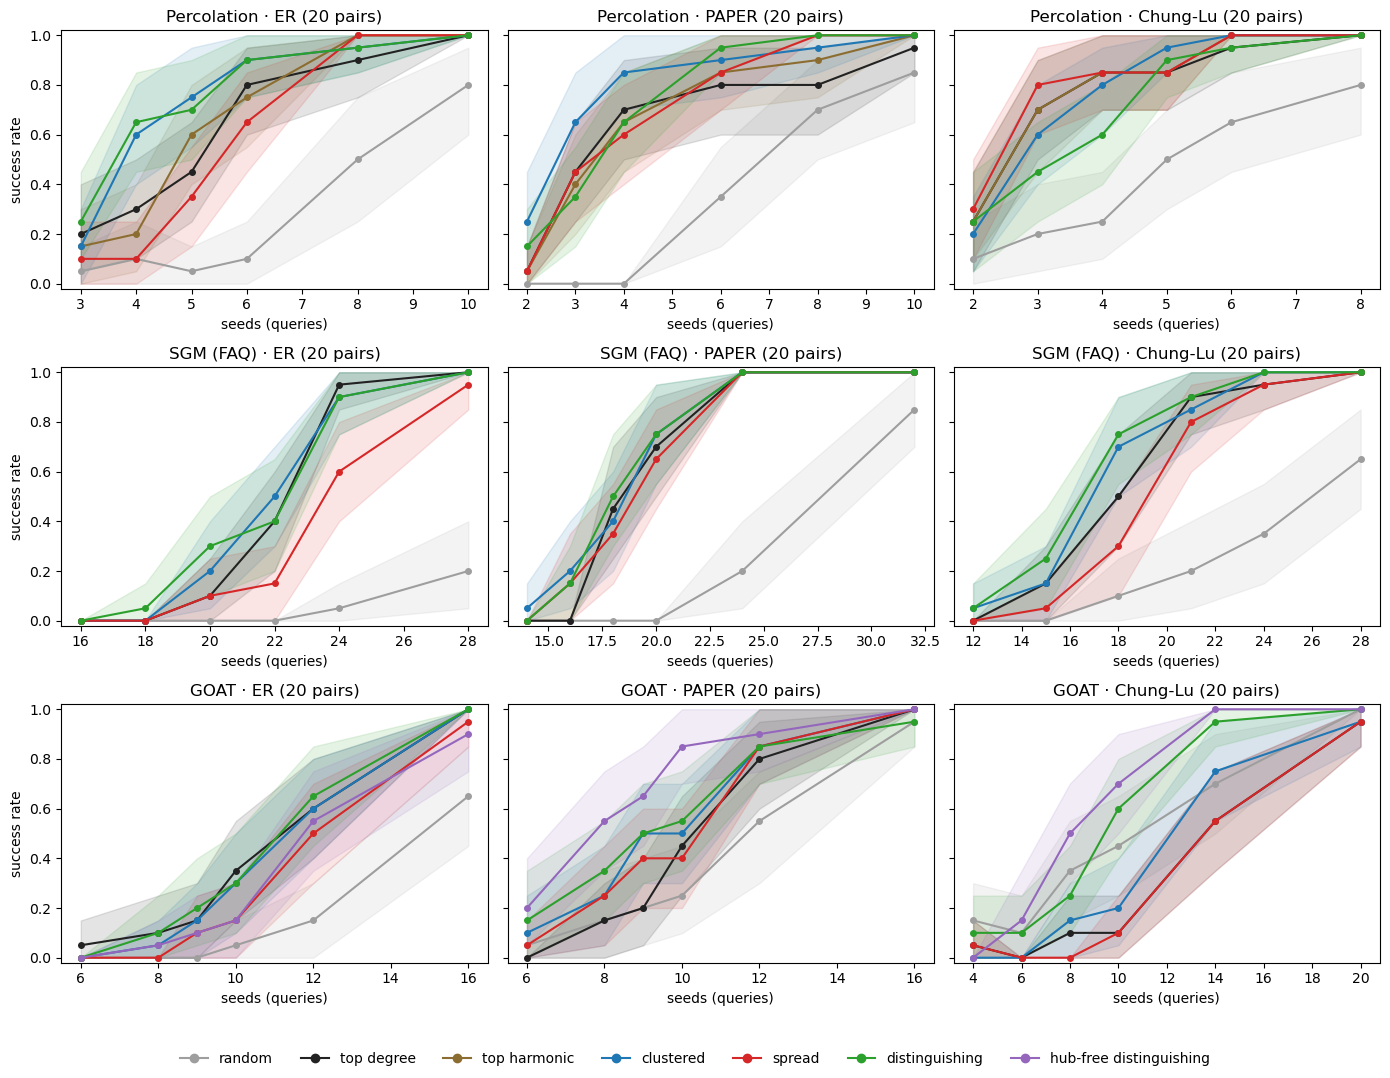

In [5]:
rng = np.random.default_rng(RANDOM_STATE)


def bootstrap_curve(matrix, n_boot=N_BOOTSTRAP):
    values = matrix.to_numpy(float)
    index = rng.integers(0, len(values), size=(n_boot, len(values)))
    means = values[index].mean(axis=1)
    return np.percentile(means, [2.5, 97.5], axis=0)


algorithms_present = [a for a in ALGORITHM_ORDER if any(d[0] == a for d in datasets)]
fig, axes = plt.subplots(len(algorithms_present), 3, figsize=(14, 3.6 * len(algorithms_present)),
                         squeeze=False, sharey=True)
for row, algorithm in enumerate(algorithms_present):
    for column, model in enumerate(MODEL_ORDER):
        ax = axes[row, column]
        data = evaluations[(evaluations['algorithm'] == algorithm) & (evaluations['model'] == model)]
        if data.empty:
            ax.set_visible(False)
            continue
        for strategy in [s for s in STRATEGY_ORDER if s in set(data['strategy'])]:
            matrix = success_matrix(data, strategy)
            low, high = bootstrap_curve(matrix)
            ax.plot(matrix.columns, matrix.mean().values, marker='o', markersize=4,
                    color=STRATEGY_COLORS[strategy], label=STRATEGY_LABELS[strategy])
            ax.fill_between(matrix.columns, low, high, color=STRATEGY_COLORS[strategy], alpha=0.12)
        n_pairs = data['pair_index'].nunique()
        ax.set_title(f'{ALGORITHM_LABELS[algorithm]} · {MODEL_LABELS[model]} ({n_pairs} pairs)')
        ax.set_xlabel('seeds (queries)')
        ax.set_ylim(-0.02, 1.02)
    axes[row, 0].set_ylabel('success rate')
strategy_legend(fig, evaluations['strategy'])
plt.tight_layout(rect=(0, 0.05, 1, 1))
save_figure(fig, 'success_curves')
plt.show()

## 3. Queries needed (k\*) and paired comparisons with top degree

**Definitions**
- k\* is the smallest budget at which the strategy succeeds on a pair. Pairs where it never succeeds within the grid are censored (`>max`).
- **Fewer / same / more:** the number of pairs on which the strategy needs fewer, the same or more queries than top degree.
- **Sign test:** compares fewer against more.
- **Mean difference:** k\* minus top degree's k\*. Censored values count as one grid step beyond the largest budget, with a bootstrap interval.
- **Mean success over grid:** the average of the success curve, i.e. the area under it.

Rows marked ★ are the pre-registered primary comparisons.

In [6]:
def k_star_table(data):
    budgets = sorted(data['budget'].unique())
    censor = budgets[-1] + (budgets[-1] - budgets[-2] if len(budgets) > 1 else 1)
    table = {}
    for strategy, part in data.groupby('strategy'):
        matrix = success_matrix(part, strategy)
        first = matrix.apply(lambda r: next((b for b, s in r.items() if s >= 1), np.inf), axis=1)
        table[strategy] = first
    return pd.DataFrame(table), censor


summary_rows, comparison_rows = [], []
k_star = {}
for algorithm, model in datasets:
    data = evaluations[(evaluations['algorithm'] == algorithm) & (evaluations['model'] == model)]
    stars, censor = k_star_table(data)
    k_star[(algorithm, model)] = stars
    budgets = sorted(data['budget'].unique())
    for strategy in [s for s in STRATEGY_ORDER if s in stars]:
        values = stars[strategy]
        finite = values[np.isfinite(values)]
        median = values.replace(np.inf, censor).median()
        summary_rows.append({
            'algorithm': ALGORITHM_LABELS[algorithm], 'model': MODEL_LABELS[model],
            'strategy': STRATEGY_LABELS[strategy], 'pairs': len(values),
            'succeeded within grid': len(finite) / len(values),
            'median k*': f'>{budgets[-1]}' if median >= censor else f'{median:g}',
            'mean success over grid': success_matrix(data, strategy).to_numpy().mean(),
        })
        if strategy == 'top_degree' or 'top_degree' not in stars:
            continue
        reference = stars['top_degree']
        fewer = int((values < reference).sum())
        more = int((values > reference).sum())
        same = len(values) - fewer - more
        difference = (values.replace(np.inf, censor) - reference.replace(np.inf, censor)).to_numpy()
        boot = difference[rng.integers(0, len(difference), size=(N_BOOTSTRAP, len(difference)))].mean(axis=1)
        low, high = np.percentile(boot, [2.5, 97.5])
        comparison_rows.append({
            'algorithm': ALGORITHM_LABELS[algorithm], 'model': MODEL_LABELS[model],
            'strategy vs top degree': ('★ ' if PRIMARY.get((algorithm, model)) == strategy else '')
                                      + STRATEGY_LABELS[strategy],
            'fewer': fewer, 'same': same, 'more': more,
            'sign-test p': binomtest(fewer, fewer + more).pvalue if fewer + more else np.nan,
            'mean difference in k*': f'{difference.mean():+.2f} [{low:+.2f}, {high:+.2f}]',
        })

k_summary = pd.DataFrame(summary_rows)
comparisons = pd.DataFrame(comparison_rows)
display(k_summary.set_index(['algorithm', 'model', 'strategy']).round(3))
if not comparisons.empty:
    display(comparisons.set_index(['algorithm', 'model', 'strategy vs top degree']).round(4))

pairs  succeeded within grid  \
algorithm   model    strategy                                                
Percolation ER       random                      20                   0.80   
                     top degree                  20                   1.00   
                     top harmonic                20                   1.00   
                     clustered                   20                   1.00   
                     spread                      20                   1.00   
                     distinguishing              20                   1.00   
            PAPER    random                      20                   0.85   
                     top degree                  20                   0.95   
                     top harmonic                20                   1.00   
                     clustered                   20                   1.00   
                     spread                      20                   1.00   
                     distinguishing              20                   1.00   
            Chung-Lu random                      20                   0.95   
                     top degree                  20                   1.00   
                     top harmonic                20                   1.00   
                     clustered                   20                   1.00   
                     spread                      20                   1.00   
                     distinguishing              20                   1.00   
SGM (FAQ)   ER       random                      20                   0.20   
                     top degree                  20                   1.00   
                     clustered                   20                   1.00   
                     spread                      20                   0.95   
                     distinguishing              20                   1.00   
            PAPER    random                      20                   0.85   
                     top degree                  20                   1.00   
                     clustered                   20                   1.00   
                     spread                      20                   1.00   
                     distinguishing              20                   1.00   
            Chung-Lu random                      20                   0.65   
                     top degree                  20                   1.00   
                     clustered                   20                   1.00   
                     spread                      20                   1.00   
                     distinguishing              20                   1.00   
GOAT        ER       random                      20                   0.65   
                     top degree                  20                   1.00   
                     clustered                   20                   1.00   
                     spread                      20                   0.95   
                     distinguishing              20                   1.00   
                     hub-free distinguishing     20                   0.90   
            PAPER    random                      20                   0.95   
                     top degree                  20                   1.00   
                     clustered                   20                   1.00   
                     spread                      20                   1.00   
                     distinguishing              20                   0.95   
                     hub-free distinguishing     20                   1.00   
            Chung-Lu random                      20                   1.00   
                     top degree                  20                   0.95   
                     clustered                   20                   0.95   
                     spread                      20                   0.95   
                     distinguishing              20                 

fewer  same  more  \
algorithm   model    strategy vs top degree                         
Percolation ER       random                         1     1    18   
                     top harmonic                   6     9     5   
                     ★ clustered                   11     5     4   
                     spread                         6     5     9   
                     distinguishing                10     8     2   
            PAPER    random                         1     1    18   
                     top harmonic                   2    13     5   
                     ★ clustered                   10     8     2   
                     spread                         2    15     3   
                     distinguishing                 5    10     5   
            Chung-Lu random                         2     3    15   
                     top harmonic                   3    15     2   
                     ★ clustered                    3    14     3   
                     spread                         4    16     0   
                     distinguishing                 4     9     7   
SGM (FAQ)   ER       random                         0     0    20   
                     clustered                      7     8     5   
                     spread                         0    11     9   
                     ★ distinguishing               6    11     3   
            PAPER    random                         0     1    19   
                     clustered                      8     7     5   
                     spread                         7     8     5   
                     ★ distinguishing               8     8     4   
            Chung-Lu random                         0     3    17   
                     clustered                      6    10     4   
                     spread                         1     9    10   
                     ★ distinguishing              10     6     4   
GOAT        ER       random                         1     5    14   
                     clustered                      6     8     6   
                     spread                         5     7     8   
                     distinguishing                 5     9     6   
                     hub-free distinguishing        5     6     9   
            PAPER    random                         4     4    12   
                     clustered                     10     8     2   
                     spread                         8     6     6   
                     distinguishing                11     3     6   
                     hub-free distinguishing       15     3     2   
            Chung-Lu random                        13     5     2   
                     clustered                      8     8     4   
                     spread                         2    14     4   
                     distinguishing                15     4     1   
                     ★ hub-free distinguishing     18     0     2   

                                                sign-test p  \
algorithm   model    strategy vs top degree                   
Percolation ER       random                          0.0001   
                     top harmonic                    1.0000   
                     ★ clustered                     0.1185   
                     spread                          0.6072   
                     distinguishing                  0.0386   
            PAPER    random                          0.0001   
                     top harmonic                    0.4531   
                     ★ clustered                     0.0386   
                     spread                          1.0000   
                     distinguishing                  1.0000   
            Chung-Lu random                          0.0023   
                     top harmonic                    1.0000   
                     ★ clustered                     1.0000   
                     spread                          0.1250   
   

## 4. Budgets needed for 50% and 90% success

The budget at which the success curve first reaches 50% or 90%, interpolated linearly between grid points, with a 95% bootstrap interval over pairs. `<=b` means the curve is already above the target at the smallest budget, and `>b` means it never reaches the target.

In [7]:
def crossing(budgets, curve, target):
    budgets = np.asarray(budgets, float)
    curve = np.asarray(curve, float)
    above = np.flatnonzero(curve >= target)
    if len(above) == 0:
        return np.inf
    i = above[0]
    if i == 0:
        return -np.inf
    x0, x1, y0, y1 = budgets[i - 1], budgets[i], curve[i - 1], curve[i]
    return x0 + (target - y0) * (x1 - x0) / (y1 - y0)


def format_budget(value, budgets):
    if value == np.inf:
        return f'>{budgets[-1]}'
    if value == -np.inf:
        return f'<={budgets[0]}'
    return f'{value:.1f}'


rows = []
for algorithm, model in datasets:
    data = evaluations[(evaluations['algorithm'] == algorithm) & (evaluations['model'] == model)]
    for strategy in [s for s in STRATEGY_ORDER if s in set(data['strategy'])]:
        matrix = success_matrix(data, strategy)
        budgets = list(matrix.columns)
        values = matrix.to_numpy(float)
        index = rng.integers(0, len(values), size=(N_BOOTSTRAP, len(values)))
        boot_curves = values[index].mean(axis=1)
        row = {'algorithm': ALGORITHM_LABELS[algorithm], 'model': MODEL_LABELS[model],
               'strategy': STRATEGY_LABELS[strategy]}
        for target in (0.5, 0.9):
            point = crossing(budgets, values.mean(axis=0), target)
            boot = np.array([crossing(budgets, curve, target) for curve in boot_curves])
            finite = boot[np.isfinite(boot)]
            interval = (f' [{np.percentile(finite, 2.5):.1f}, {np.percentile(finite, 97.5):.1f}]'
                        if len(finite) > 0.9 * len(boot) else ' [interval not available]')
            row[f'k{int(target * 100)}'] = format_budget(point, budgets) + (interval if np.isfinite(point) else '')
        rows.append(row)
display(pd.DataFrame(rows).set_index(['algorithm', 'model', 'strategy']))

k50  \
algorithm   model    strategy                                     
Percolation ER       random                      8.0 [7.2, 9.1]   
                     top degree                  5.1 [4.0, 5.6]   
                     top harmonic                4.8 [4.3, 5.6]   
                     clustered                   3.8 [3.4, 4.5]   
                     spread                      5.5 [4.8, 6.2]   
                     distinguishing              3.6 [3.2, 4.7]   
            PAPER    random                      6.9 [5.8, 8.0]   
                     top degree                  3.2 [2.8, 4.0]   
                     top harmonic                3.4 [2.8, 4.4]   
                     clustered                   2.6 [2.3, 3.2]   
                     spread                      3.3 [2.7, 4.7]   
                     distinguishing              3.5 [2.8, 4.2]   
            Chung-Lu random                      5.0 [4.2, 6.3]   
                     top degree                  2.6 [2.2, 3.0]   
                     top harmonic                2.6 [2.2, 3.0]   
                     clustered                   2.8 [2.4, 3.3]   
                     spread                      2.4 [2.1, 2.7]   
                     distinguishing              3.3 [2.5, 4.2]   
SGM (FAQ)   ER       random                                 >28   
                     top degree               22.4 [21.5, 22.9]   
                     clustered                22.0 [20.9, 22.8]   
                     spread                   23.6 [22.9, 24.9]   
                     distinguishing           22.4 [20.0, 23.0]   
            PAPER    random                   27.7 [25.8, 29.3]   
                     top degree               18.4 [17.4, 20.0]   
                     clustered                18.6 [17.0, 19.5]   
                     spread                   19.0 [17.6, 20.4]   
                     distinguishing           18.0 [17.0, 19.5]   
            Chung-Lu random                   26.0 [23.2, 28.0]   
                     top degree               18.0 [16.5, 19.2]   
                     clustered                16.9 [16.1, 18.0]   
                     spread                   19.2 [18.0, 20.1]   
                     distinguishing           16.5 [15.4, 17.5]   
GOAT        ER       random                   14.8 [13.6, 16.0]   
                     top degree                11.2 [9.8, 12.7]   
                     clustered                11.3 [10.0, 12.7]   
                     spread                   12.0 [11.1, 13.3]   
                     distinguishing           11.1 [10.0, 12.4]   
                     hub-free distinguishing  11.8 [11.0, 13.4]   
            PAPER    random                   11.7 [10.4, 13.2]   
                     top degree                10.3 [9.6, 11.3]   
                     clustered                  9.0 [8.3, 11.0]   
                     spread                    10.4 [8.5, 11.1]   
                     distinguishing             9.0 [7.6, 10.8]   
                     hub-free distinguishing     7.7 [6.8, 9.2]   
            Chung-Lu random                    10.8 [7.7, 14.0]   
                     top degree               13.6 [12.2, 15.8]   
                     clustered                12.2 [11.1, 13.6]   
                     spread                   13.6 [12.2, 15.6]   
                     distinguishing             9.4 [8.4, 10.9]   
                     hub-free distinguishing    8.0 [7.1, 10.0]   

                                                                        k90  
algorithm   model    strategy                                                
Percolation ER       random                                             >10  
                     top degree                              8.0 [5.9, 9.2]  
                     top harmonic                            7.2 [5.9, 7.6]  
                     clustered                               6.0 [4.9, 8.7]  
                     spread             

## 5. Match ratio (summer-style) and accuracy after success

The left panels show mean unseeded accuracy against budget, the summer REU plot but over unseeded vertices only. Because outcomes are all-or-nothing, this mostly reflects the success rate. The table gives mean accuracy over the evaluations that succeeded, which shows how clean a successful match is.

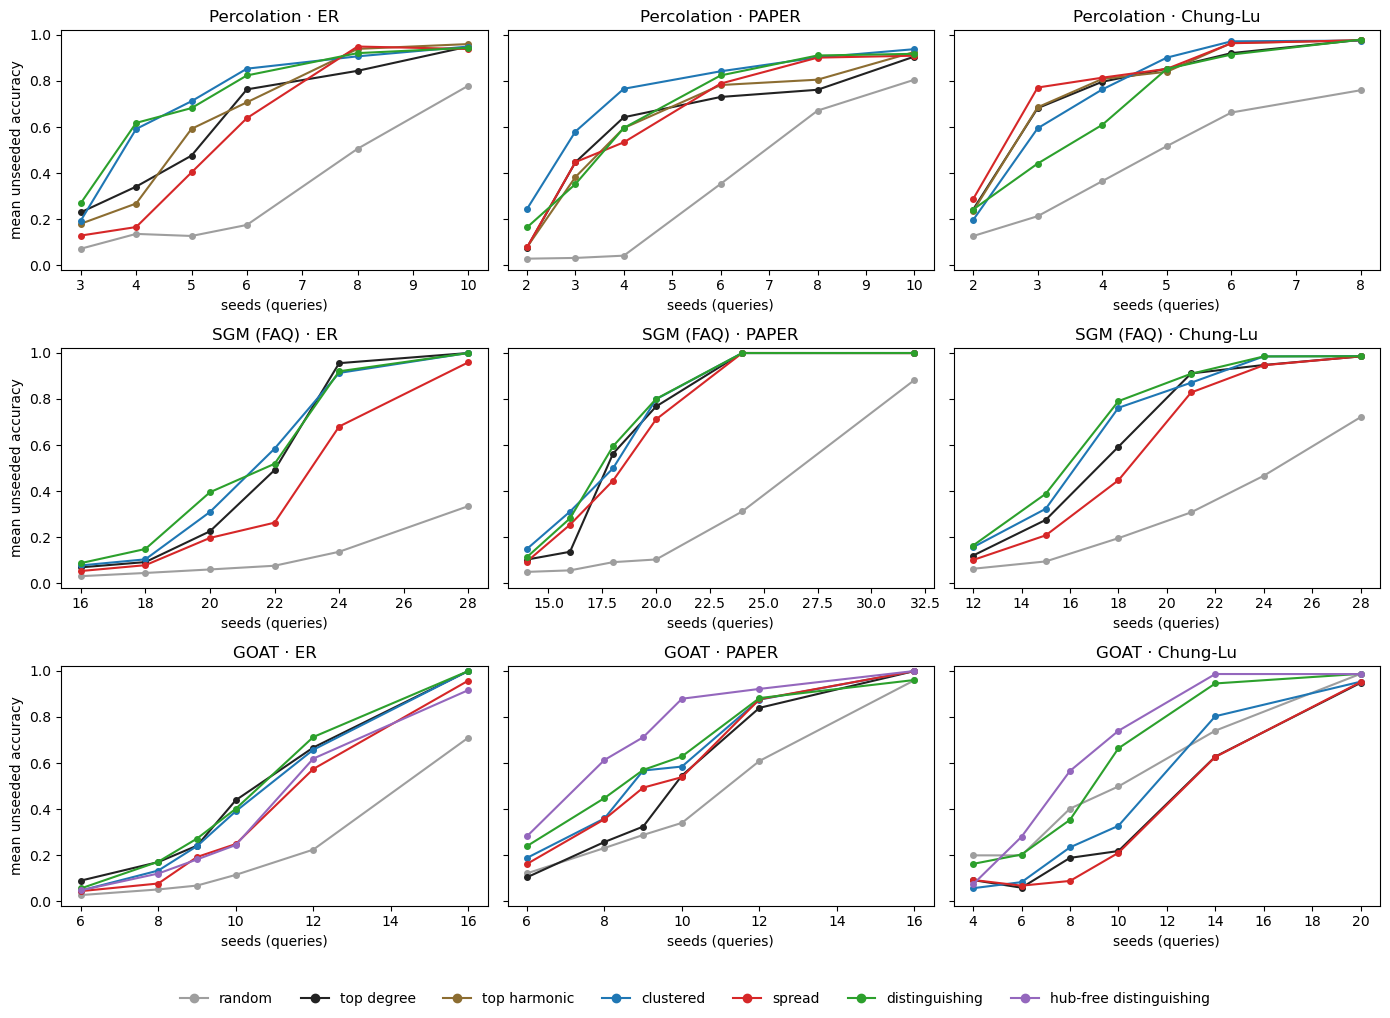

mean accuracy | success  lowest  \
algorithm   model    strategy                                                   
Percolation ER       clustered                                  0.946   0.743   
                     distinguishing                             0.934   0.739   
                     random                                     0.937   0.525   
                     spread                                     0.947   0.744   
                     top degree                                 0.945   0.797   
                     top harmonic                               0.942   0.707   
            PAPER    clustered                                  0.911   0.641   
                     distinguishing                             0.889   0.515   
                     random                                     0.929   0.694   
                     spread                                     0.901   0.676   
                     top degree                                 0.911   0.698   
                     top harmonic                               0.898   0.546   
            Chung-Lu clustered                                  0.950   0.645   
                     distinguishing                             0.938   0.522   
                     random                                     0.926   0.529   
                     spread                                     0.951   0.522   
                     top degree                                 0.948   0.522   
                     top harmonic                               0.951   0.522   
SGM (FAQ)   ER       clustered                                  1.000   0.997   
                     distinguishing                             0.999   0.993   
                     spread                                     1.000   0.993   
                     top degree                                 1.000   0.993   
                     random                                     0.999   0.997   
            PAPER    clustered                                  0.999   0.993   
                     distinguishing                             1.000   0.993   
                     random                                     0.999   0.995   
                     spread                                     0.999   0.993   
                     top degree                                 0.999   0.993   
            Chung-Lu clustered                                  0.986   0.967   
                     distinguishing                             0.986   0.970   
                     spread                                     0.986   0.962   
                     top degree                                 0.985   0.967   
                     random                                     0.985   0.967   
GOAT        ER       clustered                                  0.999   0.993   
                     distinguishing                             0.999   0.993   
                     hub-free distinguishing                    1.000   0.997   
                     random                                     1.000   0.997   
                     spread                                     1.000   0.997   
                     top degree                                 0.999   0.993   
            PAPER    clustered                                  0.999   0.993   
                     distinguishing                             1.000   0.993   
                     hub-free distinguishing                    1.000   0.993   
                     random                                     1.000   0.993   
                     spread                                     0.999   0.993   
                     top degree                                 1.000   0.993   
            Chung-Lu clustered                                  0.988   0.969   
                     distinguishing                             0.988   0.969   
                     hub-free distinguishing                    0.986   0.967

In [8]:
fig, axes = plt.subplots(len(algorithms_present), 3, figsize=(14, 3.4 * len(algorithms_present)),
                         squeeze=False, sharey=True)
for row, algorithm in enumerate(algorithms_present):
    for column, model in enumerate(MODEL_ORDER):
        ax = axes[row, column]
        data = evaluations[(evaluations['algorithm'] == algorithm) & (evaluations['model'] == model)]
        if data.empty:
            ax.set_visible(False)
            continue
        for strategy in [s for s in STRATEGY_ORDER if s in set(data['strategy'])]:
            curve = data[data['strategy'] == strategy].groupby('budget')['accuracy'].mean()
            ax.plot(curve.index, curve.values, marker='o', markersize=4, color=STRATEGY_COLORS[strategy],
                    label=STRATEGY_LABELS[strategy])
        ax.set_title(f'{ALGORITHM_LABELS[algorithm]} · {MODEL_LABELS[model]}')
        ax.set_xlabel('seeds (queries)')
        ax.set_ylim(-0.02, 1.02)
    axes[row, 0].set_ylabel('mean unseeded accuracy')
strategy_legend(fig, evaluations['strategy'])
plt.tight_layout(rect=(0, 0.05, 1, 1))
save_figure(fig, 'match_ratio_curves')
plt.show()

labelled = evaluations.assign(algorithm=evaluations['algorithm'].map(ALGORITHM_LABELS),
                              model=evaluations['model'].map(MODEL_LABELS),
                              strategy=evaluations['strategy'].map(STRATEGY_LABELS))
after_success = (labelled[labelled['success']]
                 .groupby(['algorithm', 'model', 'strategy'], sort=False)['accuracy'].agg(['mean', 'min', 'size'])
                 .rename(columns={'mean': 'mean accuracy | success', 'min': 'lowest', 'size': 'successes'}))
display(after_success.round(3))

## 6. How each strategy changed the seed sets

This is a check that each rule moved along its intended feature. It shows the mean core features of the chosen seed sets at the middle budget of each grid, as differences from top degree's sets on the same pairs.
- **Clustered** should raise pair mass.
- **Spread** should raise coverage.
- **Distinguishing** should raise signature uniqueness.
- **Hub-free** should lower degree.

In [9]:
feature_labels = {'f_degree': 'seed degree', 'f_harmonic': 'harmonic', 'f_pair_mass': 'pair mass',
                  'f_coverage': 'coverage', 'f_signature_r3': 'signature r3', 'f_signature_r2': 'signature r2'}
rows = []
for algorithm, model in datasets:
    data = evaluations[(evaluations['algorithm'] == algorithm) & (evaluations['model'] == model)]
    budgets = sorted(data['budget'].unique())
    middle = budgets[len(budgets) // 2]
    at_middle = data[data['budget'] == middle].set_index(['pair_index', 'strategy'])
    reference = at_middle.xs('top_degree', level='strategy')
    for strategy in [s for s in STRATEGY_ORDER if s in set(data['strategy']) and s != 'top_degree']:
        chosen = at_middle.xs(strategy, level='strategy')
        row = {'algorithm': ALGORITHM_LABELS[algorithm], 'model': MODEL_LABELS[model], 'budget': middle,
               'strategy': STRATEGY_LABELS[strategy]}
        for feature, label in feature_labels.items():
            row[label] = (chosen[feature] - reference[feature]).mean()
        rows.append(row)
display(pd.DataFrame(rows).set_index(['algorithm', 'model', 'budget', 'strategy']).round(3))

seed degree  harmonic  \
algorithm   model    budget strategy                                         
Percolation ER       6      random                        -9.575   -22.470   
                            top harmonic                  -0.508     0.486   
                            clustered                     -0.708    -1.547   
                            spread                        -0.158    -0.810   
                            distinguishing                -0.433    -1.347   
            PAPER    6      random                       -22.617   -45.440   
                            top harmonic                  -0.733     0.802   
                            clustered                     -3.400    -7.157   
                            spread                        -0.117    -0.759   
                            distinguishing                -3.292    -7.541   
            Chung-Lu 5      random                       -54.020   -84.774   
                            top harmonic                  -0.410     0.280   
                            clustered                     -2.140    -2.944   
                            spread                        -0.250    -0.021   
                            distinguishing                -8.290   -11.789   
SGM (FAQ)   ER       22     random                        -8.386   -19.812   
                            clustered                     -0.505    -2.095   
                            spread                        -0.355    -1.905   
                            distinguishing                -0.332    -1.524   
            PAPER    20     random                       -13.368   -27.534   
                            clustered                     -1.013    -3.540   
                            spread                        -0.560    -2.325   
                            distinguishing                -0.885    -2.820   
            Chung-Lu 21     random                       -33.717   -60.552   
                            clustered                     -0.967    -4.764   
                            spread                        -1.821    -4.289   
                            distinguishing                -3.190    -8.277   
GOAT        ER       10     random                       -10.000   -22.555   
                            clustered                     -0.675    -1.739   
                            spread                        -0.195    -1.373   
                            distinguishing                -0.255    -1.345   
                            hub-free distinguishing       -2.155    -5.097   
            PAPER    10     random                       -18.825   -35.753   
                            clustered                     -1.580    -3.870   
                            spread                        -0.325    -1.971   
                            distinguishing                -1.360    -5.042   
                            hub-free distinguishing       -9.685   -16.557   
            Chung-Lu 10     random                       -49.740   -73.795   
                            clustered                     -1.865    -3.226   
                            spread                        -1.510    -2.279   
                            distinguishing               -10.000   -14.792   
                            hub-free distinguishing      -28.385   -32.844   

                                                     pair mass  coverage  \
algorithm   model    budget strategy                                       
Percolation ER       6      random                      -0.014    -0.084   
                            top harmonic                -0.000    -0.005   
                            clustered                    0.014    -0.018   
                            spread                      -0.010     0.007   
                            distinguishing               0.003    -0.008   
            PAPER    6      random                      -0.026    -0.204   
            

## 7. Checking the predictions

**Observed order:** strategies ranked by mean success over the budget grid. A `~` marks a difference below 0.03.

**Pre-registered checks**
- **Primary comparisons:** the ★ rows of section 3.
- **What would count against the predictions:**
  - percolation: clustered does not beat spread, or falls below top degree;
  - FAQ: any strategy beats top degree by clearly more than 0.1 in mean success;
  - GOAT on Chung–Lu: top degree is not below random.

In [10]:
def observed_order(data):
    means = data.groupby('strategy')['success'].mean().sort_values(ascending=False)
    parts, previous = [], None
    for strategy, value in means.items():
        if previous is not None:
            parts.append('~' if previous - value < 0.03 else '>')
        parts.append(STRATEGY_LABELS[strategy])
        previous = value
    return ' '.join(parts)


def mean_success_difference(data, first, second):
    a = success_matrix(data, first).mean(axis=1)
    b = success_matrix(data, second).mean(axis=1)
    difference = (a - b).to_numpy()
    boot = difference[rng.integers(0, len(difference), size=(N_BOOTSTRAP, len(difference)))].mean(axis=1)
    low, high = np.percentile(boot, [2.5, 97.5])
    return difference.mean(), low, high


order_rows, check_rows = [], []
for algorithm, model in datasets:
    data = evaluations[(evaluations['algorithm'] == algorithm) & (evaluations['model'] == model)]
    order_rows.append({'algorithm': ALGORITHM_LABELS[algorithm], 'model': MODEL_LABELS[model],
                       'predicted order': PREDICTED_ORDER.get((algorithm, model), ''),
                       'observed order (mean success over grid)': observed_order(data)})
    present = set(data['strategy'])
    checks = []
    if algorithm == 'percolation':
        checks = [('clustered', 'spread', 'clustered should beat spread'),
                  ('clustered', 'top_degree', 'clustered should not fall below top degree')]
    elif algorithm == 'faq':
        checks = [(s, 'top_degree', 'should not beat top degree by clearly more than 0.1')
                  for s in STRATEGY_ORDER if s in present and s not in ('top_degree', 'random')]
    elif algorithm == 'goat' and model == 'chung_lu':
        checks = [('random', 'top_degree', 'random should be at or above top degree')]
    for first, second, expectation in checks:
        if first in present and second in present:
            mean, low, high = mean_success_difference(data, first, second)
            check_rows.append({'algorithm': ALGORITHM_LABELS[algorithm], 'model': MODEL_LABELS[model],
                               'comparison': f'{STRATEGY_LABELS[first]} - {STRATEGY_LABELS[second]}',
                               'mean success difference': f'{mean:+.3f} [{low:+.3f}, {high:+.3f}]',
                               'expectation': expectation})
display(pd.DataFrame(order_rows).set_index(['algorithm', 'model']))
if check_rows:
    display(pd.DataFrame(check_rows).set_index(['algorithm', 'model', 'comparison']))
else:
    print('No pre-registered checks apply to the strategies in this phase.')

predicted order  \
algorithm   model                                                         
Percolation ER        clustered > distinguishing >= top degree ~ top...   
            PAPER     clustered >= top harmonic >= top degree > dist...   
            Chung-Lu  clustered >= top harmonic >= top degree > dist...   
SGM (FAQ)   ER        top degree ~ distinguishing ~ clustered >= spr...   
            PAPER     distinguishing >= top degree >= spread >= clus...   
            Chung-Lu  distinguishing >= top degree >= spread >= clus...   
GOAT        ER        clustered ~ distinguishing >= top degree > random   
            PAPER     distinguishing ~ clustered >= top degree >> ra...   
            Chung-Lu     hub-free distinguishing > random >= top degree   

                                observed order (mean success over grid)  
algorithm   model                                                        
Percolation ER        distinguishing ~ clustered > top harmonic ~ to...  
            PAPER     clustered > distinguishing ~ spread ~ top harm...  
            Chung-Lu  spread ~ top harmonic ~ top degree ~ clustered...  
SGM (FAQ)   ER        distinguishing ~ clustered ~ top degree > spre...  
            PAPER     clustered ~ distinguishing > spread ~ top degr...  
            Chung-Lu  distinguishing > clustered > top degree > spre...  
GOAT        ER        distinguishing ~ top degree ~ clustered > hub-...  
            PAPER     hub-free distinguishing > distinguishing ~ clu...  
            Chung-Lu  hub-free distinguishing > distinguishing > ran...

mean success difference  \
algorithm   model    comparison                                             
Percolation ER       clustered - spread           +0.192 [+0.075, +0.300]   
                     clustered - top degree       +0.117 [-0.008, +0.250]   
            PAPER    clustered - spread           +0.108 [+0.025, +0.200]   
                     clustered - top degree       +0.142 [+0.058, +0.233]   
            Chung-Lu clustered - spread           -0.042 [-0.100, +0.008]   
                     clustered - top degree       -0.008 [-0.067, +0.058]   
SGM (FAQ)   ER       clustered - top degree       +0.025 [-0.033, +0.083]   
                     spread - top degree          -0.108 [-0.167, -0.050]   
                     distinguishing - top degree  +0.033 [-0.025, +0.083]   
            PAPER    clustered - top degree       +0.042 [-0.033, +0.117]   
                     spread - top degree          +0.000 [-0.067, +0.067]   
                     distinguishing - top degree  +0.042 [-0.017, +0.100]   
            Chung-Lu clustered - top degree       +0.042 [-0.025, +0.109]   
                     spread - top degree          -0.067 [-0.117, -0.017]   
                     distinguishing - top degree  +0.075 [-0.008, +0.158]   
GOAT        Chung-Lu random - top degree          +0.167 [+0.058, +0.267]   

                                                                                        expectation  
algorithm   model    comparison                                                                      
Percolation ER       clustered - spread                                clustered should beat spread  
                     clustered - top degree              clustered should not fall below top degree  
            PAPER    clustered - spread                                clustered should beat spread  
                     clustered - top degree              clustered should not fall below top degree  
            Chung-Lu clustered - spread                                clustered should beat spread  
                     clustered - top degree              clustered should not fall below top degree  
SGM (FAQ)   ER       clustered - top degree       should not beat top degree by clearly more tha...  
                     spread - top degree          should not beat top degree by clearly more tha...  
                     distinguishing - top degree  should not beat top degree by clearly more tha...  
            PAPER    clustered - top degree       should not beat top degree by clearly more tha...  
                     spread - top degree          should not beat top degree by clearly more tha...  
                     distinguishing - top degree  should not beat top degree by clearly more tha...  
            Chung-Lu clustered - top degree       should not beat top degree by clearly more tha...  
                     spread - top degree          should not beat top degree by clearly more tha...  
                     distinguishing - top degree  should not beat top degree by clearly more tha...  
GOAT        Chung-Lu random - top degree                    random should be at or above top degree

## 8. Run time

Run time is solver time summed over new runs. Cached runs, where two strategies chose the same seed set at the same budget, are reused rather than rerun.

In [11]:
runtime = (evaluations.groupby(['algorithm', 'model'], sort=False)
           .agg(evaluations=('success', 'size'), solver_runs=('new_runs', 'sum'),
                runs_requested=('runs', 'sum'), solver_minutes=('solver_seconds', lambda s: s.sum() / 60)))
runtime['cached share'] = 1 - runtime['solver_runs'] / runtime['runs_requested']
runtime['seconds per run'] = runtime['solver_minutes'] * 60 / runtime['solver_runs'].clip(lower=1)
pair_minutes = pair_info.groupby(['algorithm', 'model'])['pair_seconds'].sum() / 60
runtime['wall minutes (pairs)'] = pair_minutes
runtime.index = pd.MultiIndex.from_tuples([(ALGORITHM_LABELS[a], MODEL_LABELS[m]) for a, m in runtime.index],
                                          names=['algorithm', 'model'])
display(runtime.round(3))

evaluations  solver_runs  runs_requested  \
algorithm   model                                                
Percolation ER                720          667             720   
            PAPER             720          587             720   
            Chung-Lu          720          494             720   
SGM (FAQ)   ER                600         1461            1461   
            PAPER             600         1295            1295   
            Chung-Lu          600         1216            1216   
GOAT        ER                720          719             720   
            PAPER             720          717             720   
            Chung-Lu          720          677             720   

                      solver_minutes  cached share  seconds per run  \
algorithm   model                                                     
Percolation ER                 5.186         0.074            0.467   
            PAPER              4.534         0.185            0.463   
            Chung-Lu           3.855         0.314            0.468   
SGM (FAQ)   ER               120.399         0.000            4.945   
            PAPER            109.015         0.000            5.051   
            Chung-Lu         104.808         0.000            5.171   
GOAT        ER                43.443         0.001            3.625   
            PAPER             39.371         0.004            3.295   
            Chung-Lu          39.431         0.060            3.495   

                      wall minutes (pairs)  
algorithm   model                           
Percolation ER                       5.218  
            PAPER                    4.567  
            Chung-Lu                 3.886  
SGM (FAQ)   ER                     120.513  
            PAPER                  109.144  
            Chung-Lu               104.917  
GOAT        ER                      43.629  
            PAPER                   39.526  
            Chung-Lu                39.586

## 9. Seed-set features against performance

This section shows how the strategies' seed sets differ in the core features, and how those differences line up with success. It uses the saved runs only, so nothing is rerun. It needs the two cells at the top of the notebook (settings and loading), but not sections 1–8.

**Setup**
- **One budget per setting.** By default (`PLOT_BUDGET = 'balanced'`), each setting is shown at the grid budget where the success rate over all strategies is closest to 50%. That is where seed sets differ most in outcome. Two alternatives:
  - `'training'` uses the grid budget closest to the fixed-pair experiment's budget;
  - a dict such as `{('goat', 'chung_lu'): 10}` sets budgets by hand.
- **Key feature:** pair mass for percolation, and signature uniqueness for FAQ (cap 2) and GOAT (cap 3). In the core-panel refit, each of these mattered beyond degree in at least one graph model, and they are the targets of the clustered and distinguishing rules.
- **Fixed-pair score.** This comes from the core-panel logistic model (seed degree, harmonic, pair mass, signature uniqueness), fitted on the random seed sets of the fixed-pair experiment: one graph pair per setting, 600 random sets at one budget.
  - The score is the model's linear predictor in log-odds, measured from the average fixed-pair random set: 0 is a typical random set there, and +1 is one unit higher predicted log-odds of success.
  - Round 1 uses fresh pairs from the same graph models, so the score tests whether the fixed-pair model transfers to other pairs. Nothing is refitted on round 1.

**Cautions**
- **Association, not effect.** A strategy moves several features at once, so where it sits on one feature does not isolate that feature's effect.
- **Pooling pairs adds noise.** Some pairs are harder than others, which blurs the pooled plots. The within-pair concordance in 9.4 compares seed sets on the same pair and budget only, so it is the fairer summary.
- **Extrapolation.** The fixed-pair model was fitted on random sets at one budget. Most strategies' sets sit near top degree, and the plotted budget can differ from the fitted one.
- **FAQ labels differ.** Round 1 counts an FAQ success over up to 3 restarts, while the fixed-pair data used one run. So the success rates differ, and only the ranking is compared.

In [12]:
from matplotlib.lines import Line2D
from sklearn.linear_model import LogisticRegression

TRAINING_DIR = EXPERIMENT_DIR.parent / 'fixed_pair_seed_set_classification' / 'data'
PLOT_BUDGET = 'balanced'   # 'balanced', 'training', or a dict such as {('goat', 'chung_lu'): 10}
SIGNATURE_FEATURE = {'percolation': 'f_signature_r3', 'faq': 'f_signature_r2', 'goat': 'f_signature_r3'}
KEY_FEATURE = {'percolation': 'f_pair_mass', 'faq': 'f_signature_r2', 'goat': 'f_signature_r3'}
TRAINING_COLUMNS = {'f_degree': 'seed_nonseed_degree_mean', 'f_harmonic': 'seed_harmonic_mean',
                    'f_pair_mass': 'nonseed_witness_pair_mass_mean',
                    'f_signature_r2': 'nonseed_distance_signature_unique_fraction_r2',
                    'f_signature_r3': 'nonseed_distance_signature_unique_fraction_r3'}
FEATURE_NAMES = {'f_degree': 'seed degree', 'f_harmonic': 'harmonic', 'f_pair_mass': 'pair mass',
                 'f_coverage': 'coverage', 'f_signature_r2': 'signature uniqueness (cap 2)',
                 'f_signature_r3': 'signature uniqueness (cap 3)', 'score': 'fixed-pair score (log-odds)'}


def core_features(algorithm):
    return ['f_degree', 'f_harmonic', 'f_pair_mass', SIGNATURE_FEATURE[algorithm]]


def training_file(algorithm, model):
    if algorithm == 'percolation':
        folder = TRAINING_DIR / 'percolation_fixed_pairs_2026-10-07' / model
        files = sorted(folder.glob('pair_*/*_percolation_seed_sets.csv'))
    else:
        folder = TRAINING_DIR / 'sgm_fixed_pairs_2026-10-13' / algorithm / model
        files = sorted(folder.glob('pair_*/*_seed_sets.csv'))
    if len(files) != 1:
        raise FileNotFoundError(f'Expected one fixed-pair file under {folder}, found {len(files)}.')
    return files[0]


def logistic_weights(Z, y):
    return LogisticRegression(C=1e6, max_iter=5000).fit(Z, y).coef_[0]


def fit_fixed_pair(algorithm, model):
    # Core-panel model on the fixed-pair random sets, as in core_panel_refit.ipynb.
    data = pd.read_csv(training_file(algorithm, model))
    data = data[data['sampling_strategy'] == 'random']
    features = core_features(algorithm)
    X = data[[TRAINING_COLUMNS[f] for f in features]].to_numpy(float)
    if algorithm == 'percolation':
        y = (data['final_unseeded_accuracy'] >= (0.9 if PERCOLATION_LABEL == 'strict' else 0.5)).to_numpy(int)
    else:
        y = read_flag(data['sgm_success']).to_numpy(int)
    mean, sd = X.mean(axis=0), X.std(axis=0, ddof=1)
    Z = (X - mean) / sd
    # Degree-adjusted form (each feature residualised on degree): the same fitted model, used for display.
    adjusted = [Z[:, 0]]
    for j in range(1, Z.shape[1]):
        residual = Z[:, j] - np.polyval(np.polyfit(Z[:, 0], Z[:, j], 1), Z[:, 0])
        adjusted.append(residual / residual.std(ddof=1))
    return {'features': features, 'mean': mean, 'sd': sd, 'weights': logistic_weights(Z, y),
            'adjusted': logistic_weights(np.column_stack(adjusted), y),
            'sign': {f: float(np.sign(logistic_weights(Z[:, [j]], y)[0])) for j, f in enumerate(features)},
            'n_seeds': int(data['n_seeds'].iloc[0]), 'n_sets': len(y), 'success_rate': float(y.mean())}


def choose_plot_budget(algorithm, model, data, fit):
    budgets = sorted(data['budget'].unique())
    if isinstance(PLOT_BUDGET, dict) and (algorithm, model) in PLOT_BUDGET:
        return PLOT_BUDGET[(algorithm, model)]
    if PLOT_BUDGET == 'training':
        return min(budgets, key=lambda b: (abs(b - fit['n_seeds']), b))
    rates = data.groupby('budget')['success'].mean()
    return min(budgets, key=lambda b: (abs(rates[b] - 0.5), b))


scored = evaluations.copy()
scored['score'] = np.nan
fits, plot_budgets, model_rows = {}, {}, []
for algorithm, model in datasets:
    fit = fits[(algorithm, model)] = fit_fixed_pair(algorithm, model)
    rows = (scored['algorithm'] == algorithm) & (scored['model'] == model)
    Z = (scored.loc[rows, fit['features']].to_numpy(float) - fit['mean']) / fit['sd']
    scored.loc[rows, 'score'] = Z @ fit['weights']
    data = scored[rows]
    budget = plot_budgets[(algorithm, model)] = choose_plot_budget(algorithm, model, data, fit)
    model_rows.append({
        'algorithm': ALGORITHM_LABELS[algorithm], 'model': MODEL_LABELS[model],
        'fixed-pair budget': fit['n_seeds'], 'fixed-pair success': fit['success_rate'],
        'degree': fit['adjusted'][0], 'harmonic | deg': fit['adjusted'][1],
        'pair mass | deg': fit['adjusted'][2], 'signature | deg': fit['adjusted'][3],
        'signature cap': int(SIGNATURE_FEATURE[algorithm][-1]),
        'plotted budget': budget, 'round-1 success there': data.loc[data['budget'] == budget, 'success'].mean(),
    })

feature_algorithms = [a for a in ALGORITHM_ORDER if any(d[0] == a for d in datasets)]
plotted_strategies = set(scored.loc[scored['algorithm'].isin(feature_algorithms), 'strategy'])
print('Fixed-pair models: log-odds per SD of the fixed-pair random sets, degree-adjusted form.')
display(pd.DataFrame(model_rows).set_index(['algorithm', 'model']).round(2))


def panel_data(algorithm, model):
    data = scored[(scored['algorithm'] == algorithm) & (scored['model'] == model)]
    budget = plot_budgets[(algorithm, model)]
    return data[data['budget'] == budget], budget


def panel_title(algorithm, model, budget, data):
    return (f'{ALGORITHM_LABELS[algorithm]} · {MODEL_LABELS[model]} · {budget} seeds '
            f'({data["pair_index"].nunique()} pairs)')


def present_strategies(data):
    return [s for s in STRATEGY_ORDER if s in set(data['strategy'])]


def finish_feature_figure(fig, strategies, extra, name):
    # Two legend rows below the panels: strategies, then marker meanings.
    height = fig.get_figheight()
    handles = [Line2D([0], [0], color=STRATEGY_COLORS[s], marker='o', linestyle='', label=STRATEGY_LABELS[s])
               for s in STRATEGY_ORDER if s in set(strategies)]
    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.32 / height), ncol=len(handles),
               frameon=False)
    fig.legend(handles=list(extra), loc='lower center', bbox_to_anchor=(0.5, 0.02 / height), ncol=len(extra),
               frameon=False)
    plt.tight_layout(rect=(0, 0.75 / height, 1, 1))
    save_figure(fig, name)
    plt.show()


def bootstrap_mean_interval(values, generator):
    values = np.asarray(values, float)
    index = generator.integers(0, len(values), size=(N_BOOTSTRAP, len(values)))
    return np.percentile(values[index].mean(axis=1), [2.5, 97.5])


def plot_success_against(column, name):
    generator = np.random.default_rng(RANDOM_STATE + 9)
    fig, axes = plt.subplots(len(feature_algorithms), 3, figsize=(14, 3.8 * len(feature_algorithms)),
                             squeeze=False)
    for row, algorithm in enumerate(feature_algorithms):
        x_column = KEY_FEATURE[algorithm] if column == 'key' else column
        for col, model in enumerate(MODEL_ORDER):
            ax = axes[row, col]
            if (algorithm, model) not in plot_budgets:
                ax.set_visible(False)
                continue
            data, budget = panel_data(algorithm, model)
            # All seed sets in the panel, in five equal-size bins of x.
            bins = pd.qcut(data[x_column].rank(method='first'), 5, labels=False)
            binned = data.groupby(bins).agg(x=(x_column, 'mean'), rate=('success', 'mean'))
            ax.plot(binned['x'], binned['rate'], color='#BBBBBB', linewidth=2.5, marker='s', markersize=4,
                    zorder=1)
            for strategy in present_strategies(data):
                part = data[data['strategy'] == strategy]
                x, y = part[x_column].to_numpy(float), part['success'].to_numpy(float)
                (x_low, x_high) = bootstrap_mean_interval(x, generator)
                (y_low, y_high) = bootstrap_mean_interval(y, generator)
                ax.errorbar(x.mean(), y.mean(), xerr=[[x.mean() - x_low], [x_high - x.mean()]],
                            yerr=[[y.mean() - y_low], [y_high - y.mean()]], fmt='o', markersize=7,
                            color=STRATEGY_COLORS[strategy], markeredgecolor='black', markeredgewidth=0.6,
                            elinewidth=1, capsize=2, zorder=3)
            ax.set_title(panel_title(algorithm, model, budget, data), fontsize=10)
            ax.set_xlabel(FEATURE_NAMES.get(x_column, x_column))
            ax.set_ylim(-0.04, 1.04)
        axes[row, 0].set_ylabel('success rate')
    extra = [Line2D([0], [0], color='grey', marker='o', markeredgecolor='black', linestyle='-', linewidth=1,
                    label='strategy: mean x and success rate, 95% intervals'),
             Line2D([0], [0], color='#BBBBBB', linewidth=2.5, marker='s', markersize=4,
                    label='all seed sets in 5 equal-size bins of x')]
    finish_feature_figure(fig, plotted_strategies, extra, name)

Fixed-pair models: log-odds per SD of the fixed-pair random sets, degree-adjusted form.


fixed-pair budget  fixed-pair success  degree  \
algorithm   model                                                     
Percolation ER                        8                0.51    0.64   
            PAPER                     7                0.61    0.63   
            Chung-Lu                  5                0.50    0.53   
SGM (FAQ)   ER                       29                0.74    0.44   
            PAPER                    31                0.53    0.54   
            Chung-Lu                 27                0.69    0.24   
GOAT        ER                       12                0.67    0.26   
            PAPER                    12                0.27    0.47   
            Chung-Lu                  9                0.67   -0.18   

                      harmonic | deg  pair mass | deg  signature | deg  \
algorithm   model                                                        
Percolation ER                 -0.05             0.60             0.33   
            PAPER               0.56             0.94            -0.18   
            Chung-Lu            0.48             0.61             0.08   
SGM (FAQ)   ER                  0.03             0.08             0.12   
            PAPER              -0.03            -0.05             0.31   
            Chung-Lu            0.39            -0.05             0.16   
GOAT        ER                  0.14             0.12             0.12   
            PAPER              -0.17             0.06             0.13   
            Chung-Lu           -0.16             0.04             0.42   

                      signature cap  plotted budget  round-1 success there  
algorithm   model                                                           
Percolation ER                    3               5                   0.48  
            PAPER                 3               4                   0.57  
            Chung-Lu              3               3                   0.57  
SGM (FAQ)   ER                    2              24                   0.68  
            PAPER                 2              20                   0.57  
            Chung-Lu              2              18                   0.47  
GOAT        ER                    3              12                   0.51  
            PAPER                 3              10                   0.50  
            Chung-Lu              3              10                   0.36

### 9.1 Where each strategy puts its seeds

Each panel plots seed degree against the algorithm's key feature, at the budget in the title. Seed degree is the mean number of non-seed neighbours per seed.
- **Small markers** are single seed sets, one per pair and strategy. They are filled if that set succeeded and hollow if it failed.
- **Diamonds** are strategy means.

**What to look for**
- **Did the rules land where they were meant to?** Compared with top degree:
  - clustered should sit higher in pair mass (percolation row);
  - distinguishing should sit higher in signature uniqueness (FAQ and GOAT rows);
  - hub-free distinguishing should sit lower in degree.
- **Do the filled markers gather in one region of the plane?**

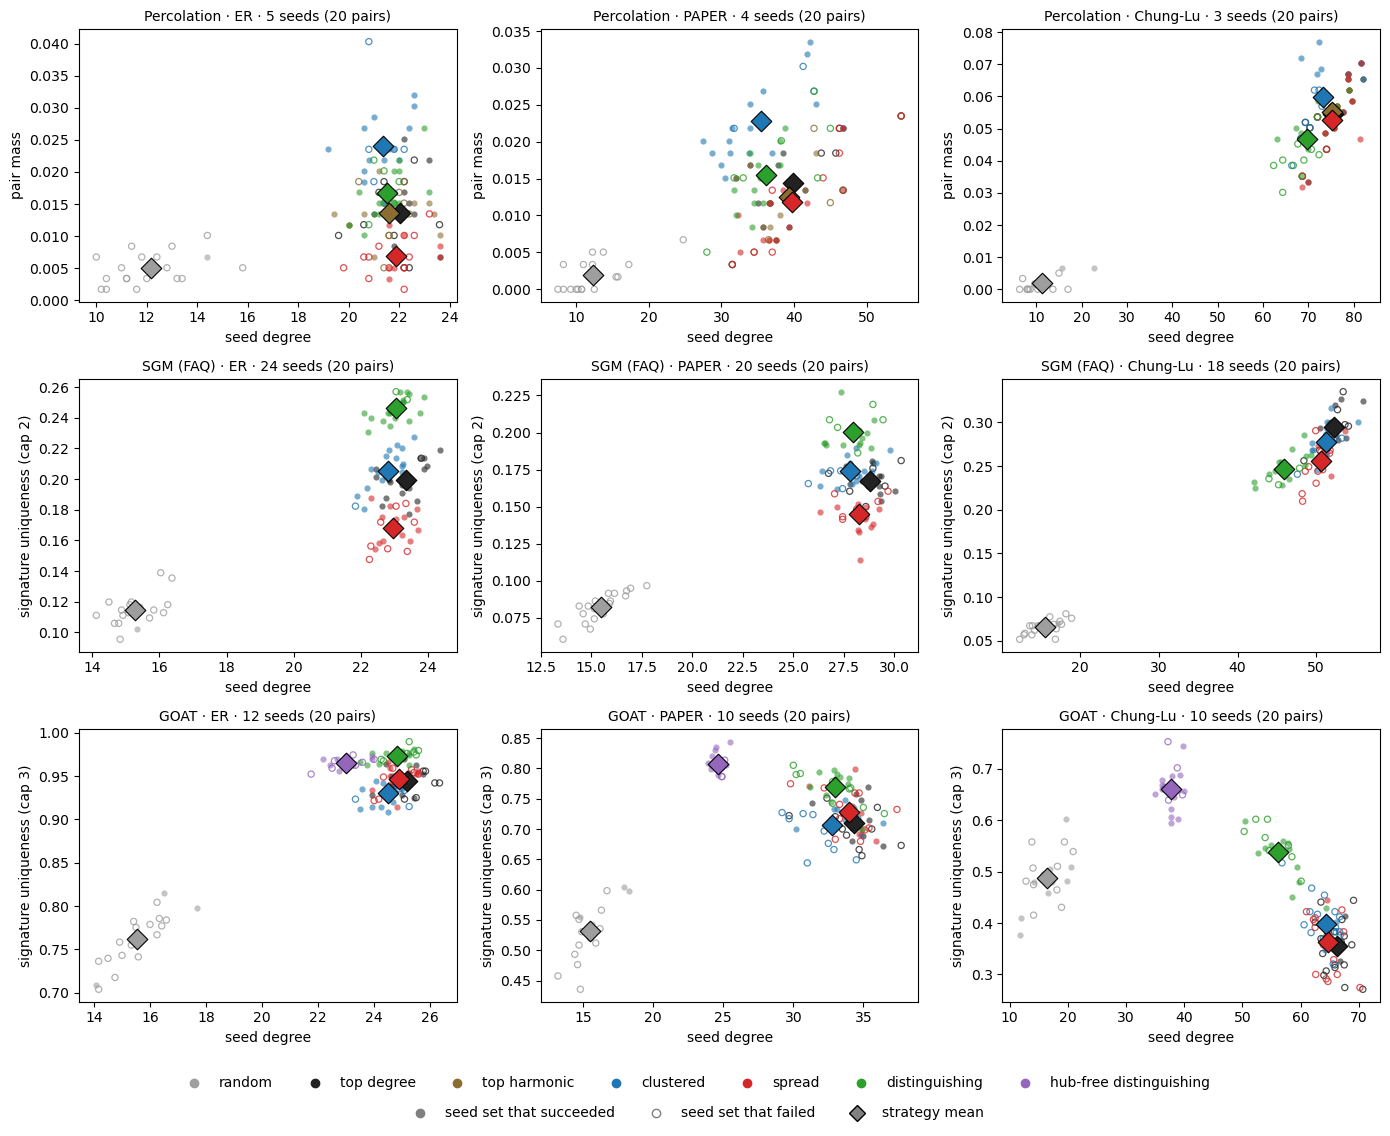

In [13]:
fig, axes = plt.subplots(len(feature_algorithms), 3, figsize=(14, 3.8 * len(feature_algorithms)), squeeze=False)
for row, algorithm in enumerate(feature_algorithms):
    y_column = KEY_FEATURE[algorithm]
    for col, model in enumerate(MODEL_ORDER):
        ax = axes[row, col]
        if (algorithm, model) not in plot_budgets:
            ax.set_visible(False)
            continue
        data, budget = panel_data(algorithm, model)
        for strategy in present_strategies(data):
            part = data[data['strategy'] == strategy]
            color = STRATEGY_COLORS[strategy]
            x, y = part['f_degree'].to_numpy(float), part[y_column].to_numpy(float)
            succeeded = part['success'].to_numpy(bool)
            ax.scatter(x[succeeded], y[succeeded], s=20, color=color, alpha=0.6, linewidths=0, zorder=2)
            ax.scatter(x[~succeeded], y[~succeeded], s=20, facecolors='none', edgecolors=color, alpha=0.8,
                       linewidths=0.9, zorder=2)
            ax.scatter(x.mean(), y.mean(), s=110, marker='D', color=color, edgecolors='black', linewidths=0.8,
                       zorder=4)
        ax.set_title(panel_title(algorithm, model, budget, data), fontsize=10)
        ax.set_xlabel(FEATURE_NAMES['f_degree'])
        ax.set_ylabel(FEATURE_NAMES[y_column])
marker_handles = [
    Line2D([0], [0], marker='o', color='grey', linestyle='', label='seed set that succeeded'),
    Line2D([0], [0], marker='o', markerfacecolor='none', markeredgecolor='grey', linestyle='',
           label='seed set that failed'),
    Line2D([0], [0], marker='D', color='grey', markeredgecolor='black', linestyle='', markersize=8,
           label='strategy mean'),
]
finish_feature_figure(fig, plotted_strategies, marker_handles, 'feature_map')

### 9.2 Success against the key feature

Each strategy is one point: its mean key feature (x) and its success rate (y) at the plotted budget. The bars are 95% bootstrap intervals over pairs, in both directions.

The grey line pools all seed sets in the panel. It sorts them by the key feature, splits them into five equal-size bins, and shows each bin's success rate.

If the feature explains the differences between strategies, the strategy points sit close to the grey line and rise from left to right.

To plot another feature, change the argument, for example `plot_success_against('f_degree', 'success_vs_degree')`.

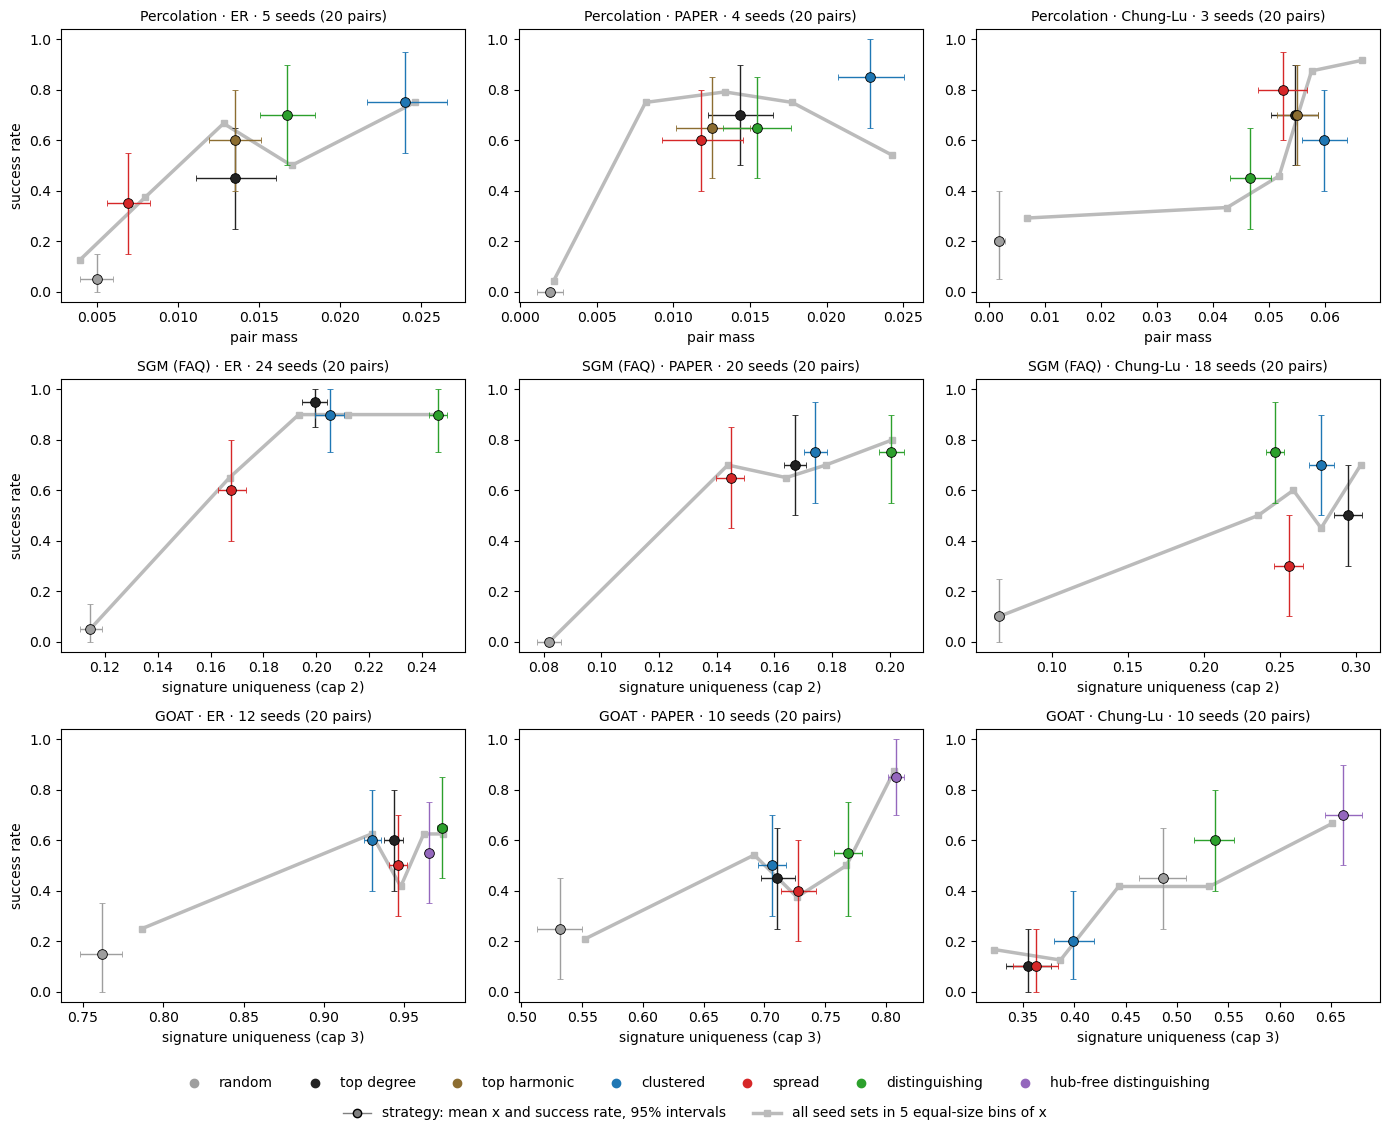

In [14]:
plot_success_against('key', 'success_vs_key_feature')

### 9.3 Success against the fixed-pair score

This is the same plot with the fixed-pair score on the x-axis. The score comes from the core-panel model fitted on the fixed-pair experiment and is applied unchanged to round-1 seed sets.

If the model transfers to new pairs, a higher score should mean a higher success rate.

The score is measured from the average fixed-pair random set, which was drawn at the fixed-pair budget. Its level therefore shifts with the plotted budget, so compare points within a panel, not across panels.

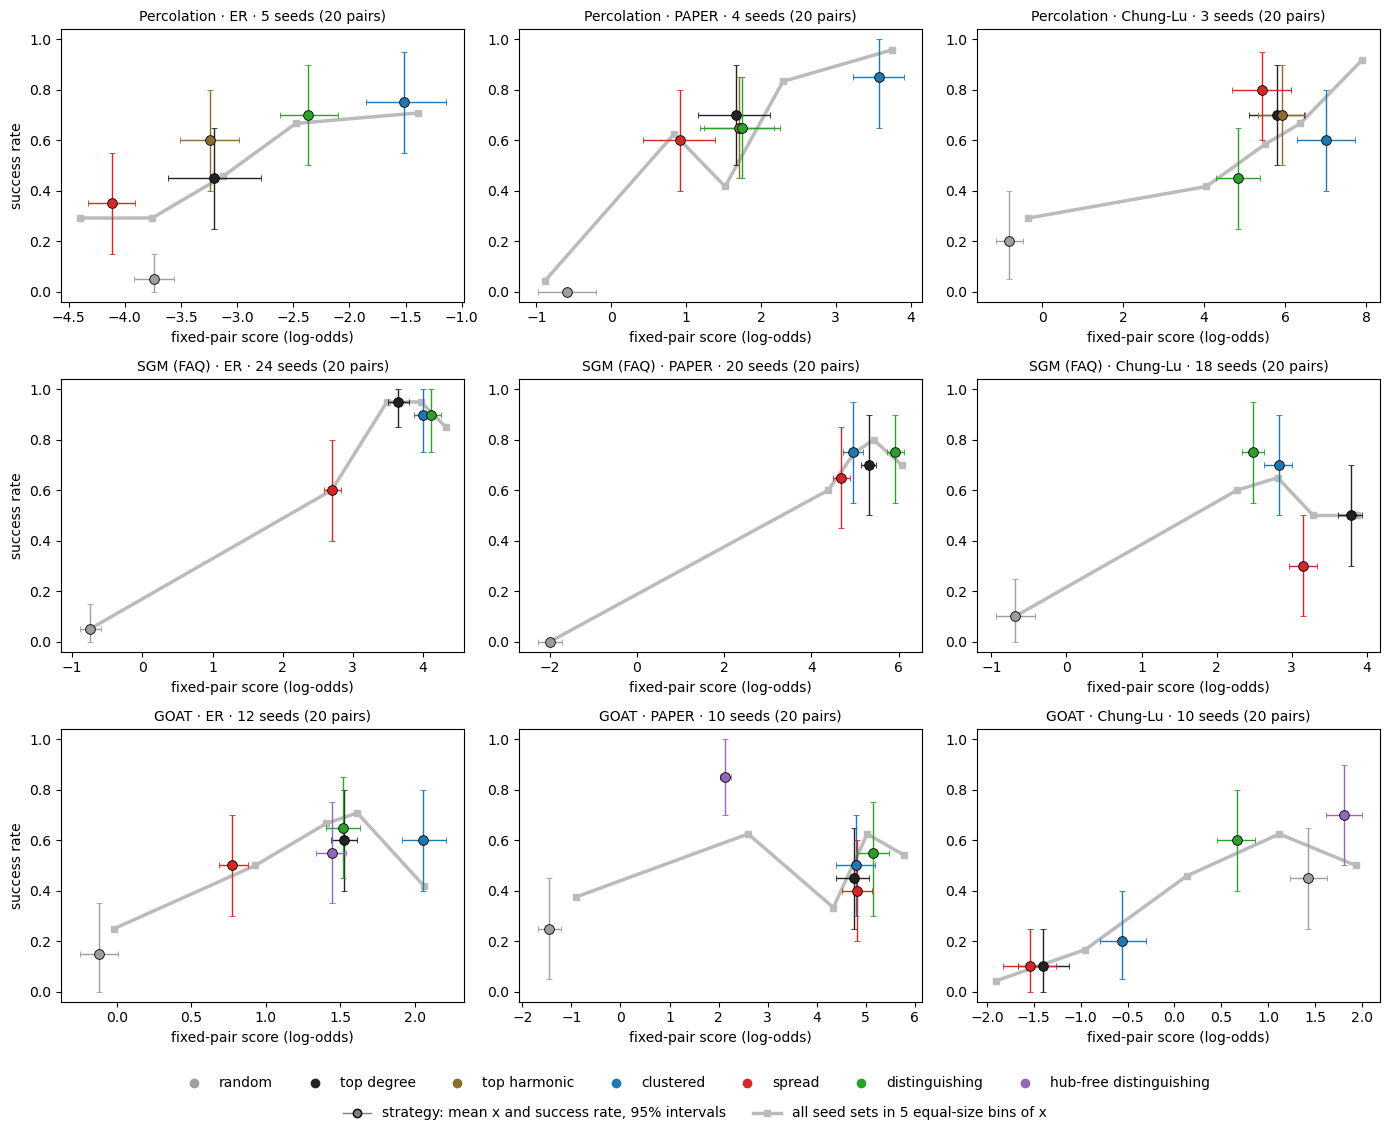

In [15]:
plot_success_against('score', 'success_vs_fixed_pair_score')

### 9.4 Does the fixed-pair model rank seed sets on new pairs?

**Within-pair concordance**
- **Couples:** for every pair and budget, each seed set that succeeded is matched with each set that failed.
- **Concordance:** the share of these couples in which the set that succeeded has the higher score. Ties count as half.
- **Reading it:** 0.5 is chance and 1 is perfect. It is an AUC computed within pairs, so differences in difficulty between pairs do not enter.
- **Data:** all grid budgets are used. The intervals are 95% bootstraps over pairs.

**Scorers.** All are fitted on the fixed-pair random sets.
- **Fixed-pair score:** the four-feature core-panel model.
- **Seed degree only** and **key feature only:** one-feature models, where only the sign matters for ranking. For example, the fitted degree effect on GOAT Chung–Lu is negative, so there lower degree ranks higher.

**Sets**
- **All strategies** includes the random sets. These are far from the rest and usually easy to rank.
- **Without random** compares only the designed rules, which all sit near top degree. This is the harder test, and the one that matters for choosing between rules.

In [16]:
def within_pair_concordance(data, column, sign, generator):
    rows = []
    for (pair, budget), part in data.groupby(['pair_index', 'budget']):
        succeeded = part['success'].to_numpy(bool)
        if succeeded.all() or not succeeded.any():
            continue
        values = sign * part[column].to_numpy(float)
        difference = values[succeeded][:, None] - values[~succeeded][None, :]
        tied = np.isclose(difference, 0.0, atol=1e-12)
        rows.append((pair, np.sum((difference > 0) & ~tied) + 0.5 * np.sum(tied), difference.size))
    if not rows:
        return np.nan, np.nan, np.nan, 0
    per_pair = pd.DataFrame(rows, columns=['pair', 'concordant', 'couples']).groupby('pair').sum()
    concordant, couples = per_pair['concordant'].to_numpy(float), per_pair['couples'].to_numpy(float)
    index = generator.integers(0, len(couples), size=(N_BOOTSTRAP, len(couples)))
    boot = concordant[index].sum(axis=1) / couples[index].sum(axis=1)
    low, high = np.percentile(boot, [2.5, 97.5])
    return concordant.sum() / couples.sum(), low, high, int(couples.sum())


concordance_rng = np.random.default_rng(RANDOM_STATE + 94)
concordance_rows = []
for algorithm, model in datasets:
    fit = fits[(algorithm, model)]
    key = KEY_FEATURE[algorithm]
    scorers = {'fixed-pair score': ('score', 1.0),
               'seed degree only': ('f_degree', fit['sign']['f_degree']),
               'key feature only': (key, fit['sign'][key])}
    data = scored[(scored['algorithm'] == algorithm) & (scored['model'] == model)]
    for sets, part in [('all strategies', data), ('without random', data[data['strategy'] != 'random'])]:
        row = {'algorithm': ALGORITHM_LABELS[algorithm], 'model': MODEL_LABELS[model], 'sets': sets,
               'key feature': FEATURE_NAMES[key]}
        for name, (column, sign) in scorers.items():
            value, low, high, couples = within_pair_concordance(part, column, sign, concordance_rng)
            row['couples'] = couples
            row[name] = f'{value:.2f} [{low:.2f}, {high:.2f}]' if couples else 'no couples'
        concordance_rows.append(row)

concordance_table = pd.DataFrame(concordance_rows).set_index(['algorithm', 'model', 'sets'])
display(concordance_table[['key feature', 'couples', 'fixed-pair score', 'seed degree only', 'key feature only']])

key feature  couples  \
algorithm   model    sets                                                    
Percolation ER       all strategies                     pair mass      503   
                     without random                     pair mass      266   
            PAPER    all strategies                     pair mass      427   
                     without random                     pair mass      190   
            Chung-Lu all strategies                     pair mass      399   
                     without random                     pair mass      148   
SGM (FAQ)   ER       all strategies  signature uniqueness (cap 2)      256   
                     without random  signature uniqueness (cap 2)       84   
            PAPER    all strategies  signature uniqueness (cap 2)      270   
                     without random  signature uniqueness (cap 2)       92   
            Chung-Lu all strategies  signature uniqueness (cap 2)      294   
                     without random  signature uniqueness (cap 2)      108   
GOAT        ER       all strategies  signature uniqueness (cap 3)      358   
                     without random  signature uniqueness (cap 3)      216   
            PAPER    all strategies  signature uniqueness (cap 3)      446   
                     without random  signature uniqueness (cap 3)      280   
            Chung-Lu all strategies  signature uniqueness (cap 3)      395   
                     without random  signature uniqueness (cap 3)      246   

                                      fixed-pair score   seed degree only  \
algorithm   model    sets                                                   
Percolation ER       all strategies  0.78 [0.72, 0.84]  0.66 [0.58, 0.74]   
                     without random  0.73 [0.63, 0.82]  0.37 [0.25, 0.51]   
            PAPER    all strategies  0.76 [0.69, 0.83]  0.68 [0.60, 0.76]   
                     without random  0.67 [0.53, 0.78]  0.34 [0.25, 0.44]   
            Chung-Lu all strategies  0.78 [0.64, 0.89]  0.82 [0.70, 0.92]   
                     without random  0.57 [0.38, 0.74]  0.66 [0.46, 0.84]   
SGM (FAQ)   ER       all strategies  0.94 [0.91, 0.96]  0.85 [0.79, 0.91]   
                     without random  0.82 [0.73, 0.90]  0.55 [0.38, 0.72]   
            PAPER    all strategies  0.86 [0.80, 0.91]  0.81 [0.76, 0.86]   
                     without random  0.58 [0.42, 0.72]  0.44 [0.31, 0.56]   
            Chung-Lu all strategies  0.79 [0.72, 0.84]  0.79 [0.70, 0.85]   
                     without random  0.44 [0.31, 0.56]  0.44 [0.32, 0.56]   
GOAT        ER       all strategies  0.71 [0.62, 0.80]  0.70 [0.60, 0.79]   
                     without random  0.58 [0.43, 0.72]  0.56 [0.41, 0.71]   
            PAPER    all strategies  0.55 [0.46, 0.64]  0.48 [0.40, 0.56]   
                     without random  0.39 [0.30, 0.48]  0.28 [0.20, 0.36]   
            Chung-Lu all strategies  0.79 [0.71, 0.87]  0.78 [0.68, 0.87]   
                     without random  0.85 [0.77, 0.92]  0.87 [0.77, 0.93]   

                                      key feature only  
algorithm   model    sets                               
Percolation ER       all strategies  0.84 [0.78, 0.89]  
                     without random  0.74 [0.63, 0.83]  
            PAPER    all strategies  0.81 [0.74, 0.87]  
                     without random  0.62 [0.49, 0.73]  
            Chung-Lu all strategies  0.79 [0.68, 0.89]  
                     without random  0.59 [0.41, 0.75]  
SGM (FAQ)   ER       all strategies  0.94 [0.91, 0.97]  
                     without random  0.83 [0.75, 0.90]  
            PAPER    all strategies  0.86 [0.81, 0.91]  
                     without random  0.59 [0.45, 0.72]  
            Chung-Lu all strategies  0.81 [0.75, 0.87]  
                     without random  0.51 [0.40, 0.62]  
GOAT        ER       all strategies  0.66 [0.58, 0.72]  
                     without random  0.49 [0.42, 0.56]  
            PAPER    all strategies  0.7

## 10. Individual seed sets: actual feature values and final performance

This section replaces strategy averages with **one dot per strategy's seed set on one graph pair**. The two columns show a raw feature and the frozen four-feature score; the y-axis is actual final unseeded accuracy. Orange diamonds summarize mean accuracy in bins of the x value, with 95% intervals obtained by resampling whole graph pairs. No trend shape is imposed and the diamonds are not connected.

**Run:** execute the notebook's settings and loading cells at the top, then the **first code cell of section 9** (the model/score setup), then this section. Sections 1–8 and the remaining section-9 plots are not required. Everything here reads existing data; no matchers are run and no model is fitted to the round-1 evaluation outcomes.

The default reproduces the GOAT Chung–Lu example at 10 seeds. Set `SCATTER_SETTINGS = 'all'` to generate the figures for all available settings, or provide a list of `(algorithm, model)` pairs. Change `SCATTER_FEATURE` to examine degree, centrality or another recorded feature. Each figure always holds the seed budget fixed.

The score is $\sum_j \beta_j (f_j-\mu_j)/\sigma_j$, using weights and scales from the separate fixed-pair random sets. Zero is the average training score; it is **not a success probability**. The training budget is listed in section 9 and may differ from the plotted budget.

In [17]:
required_scatter_state = ['scored', 'fits', 'plot_budgets', 'KEY_FEATURE', 'FEATURE_NAMES']
missing_scatter_state = [name for name in required_scatter_state if name not in globals()]
if missing_scatter_state:
    raise RuntimeError('Run the settings/loading cells and the first code cell of section 9 first. '
                       'Missing: ' + ', '.join(missing_scatter_state))

SCATTER_SETTINGS = 'all'  # 'all', or e.g. [('percolation', 'sparse_er'), ('goat', 'paper_pa')]
SCATTER_BUDGETS = {('goat', 'chung_lu'): 10}  # unspecified settings use section 9's selected budget
SCATTER_FEATURE = 'key'                      # 'key', 'f_degree', 'f_harmonic', 'f_pair_mass', 'f_coverage', etc.
SCATTER_N_BINS = 5
SCATTER_BOOTSTRAPS = N_BOOTSTRAP
SCATTER_RANDOM_SEED = RANDOM_STATE + 100
SCATTER_INCLUDE_RANDOM = True                # applies to the absolute-value plots
SCATTER_PAIRED_INCLUDE_RANDOM = False        # paired plots compare designed alternatives with top degree

scatter_settings = list(datasets) if SCATTER_SETTINGS == 'all' else [tuple(s) for s in SCATTER_SETTINGS]
if len(scatter_settings) != len(set(scatter_settings)):
    raise ValueError('List each setting only once.')
if SCATTER_N_BINS < 1 or SCATTER_BOOTSTRAPS < 1:
    raise ValueError('The bin count and bootstrap count must be positive.')
for setting in scatter_settings:
    if setting not in fits:
        raise ValueError(f'Unavailable setting: {setting}. Available: {list(fits)}')

scatter_bin_tables = []
print('Settings:', scatter_settings)
print('Figures use the notebook SAVE_FIGURES setting; set it to True to export PNG and PDF files.')

Settings: [('percolation', 'sparse_er'), ('percolation', 'paper_pa'), ('percolation', 'chung_lu'), ('faq', 'sparse_er'), ('faq', 'paper_pa'), ('faq', 'chung_lu'), ('goat', 'sparse_er'), ('goat', 'paper_pa'), ('goat', 'chung_lu')]
Figures use the notebook SAVE_FIGURES setting; set it to True to export PNG and PDF files.


In [22]:
SCATTER_BIN_COLOR = '#E66100'  # orange, so the bin markers differ from every rule's colour


def scatter_binned_accuracy(frame, x_column, n_bins=5, n_boot=2000, seed=2026):
    """Observed x bins and accuracy means; cluster bootstrap resamples complete pairs.

    Tied x values stay together. Constant features produce one bin. A bin's
    interval is omitted with fewer than two contributing pairs or when fewer
    than 90% of cluster resamples contain observations in that bin.
    """
    data = frame[['pair_index', x_column, 'accuracy']].copy()
    data = data[np.isfinite(data[x_column]) & np.isfinite(data['accuracy'])].copy()
    columns = ['bin', 'n_sets', 'n_pairs', 'x_min', 'x_max', 'x_mean', 'mean_accuracy',
               'ci_low', 'ci_high', 'valid_bootstraps']
    if data.empty:
        return pd.DataFrame(columns=columns)
    unique = data[x_column].nunique()
    if unique == 1 or n_bins == 1:
        data['_bin'] = 0
    else:
        data['_bin'] = pd.qcut(data[x_column], q=min(n_bins, unique), labels=False, duplicates='drop')
    if data['_bin'].isna().any():
        raise ValueError('Unexpected missing bin assignment.')
    pair_ids = np.sort(data['pair_index'].unique())
    bin_ids = np.sort(data['_bin'].unique())
    totals = np.zeros((len(pair_ids), len(bin_ids)))
    counts = np.zeros_like(totals)
    for i, pair in enumerate(pair_ids):
        part = data[data['pair_index'] == pair]
        for j, bin_id in enumerate(bin_ids):
            values = part.loc[part['_bin'] == bin_id, 'accuracy']
            counts[i, j], totals[i, j] = len(values), values.sum()
    rng_scatter = np.random.default_rng(seed)
    indices = rng_scatter.integers(0, len(pair_ids), size=(n_boot, len(pair_ids)))
    boot_count, boot_sum = counts[indices].sum(axis=1), totals[indices].sum(axis=1)
    boot_means = np.divide(boot_sum, boot_count, out=np.full_like(boot_sum, np.nan), where=boot_count > 0)
    rows = []
    for j, bin_id in enumerate(bin_ids):
        part = data[data['_bin'] == bin_id]
        draws = boot_means[:, j]
        finite = draws[np.isfinite(draws)]
        low, high = np.nan, np.nan
        if part['pair_index'].nunique() >= 2 and len(finite) >= .9*n_boot:
            low, high = np.percentile(finite, [2.5, 97.5])
        rows.append(dict(bin=int(bin_id)+1, n_sets=len(part), n_pairs=part['pair_index'].nunique(),
                         x_min=part[x_column].min(), x_max=part[x_column].max(), x_mean=part[x_column].mean(),
                         mean_accuracy=part['accuracy'].mean(), ci_low=low, ci_high=high,
                         valid_bootstraps=len(finite)))
    return pd.DataFrame(rows, columns=columns)


def scatter_panel_data(algorithm, model):
    data = scored[(scored['algorithm'] == algorithm) & (scored['model'] == model)].copy()
    budget = SCATTER_BUDGETS.get((algorithm, model), plot_budgets[(algorithm, model)])
    available = sorted(data['budget'].unique())
    if budget not in available:
        raise ValueError(f'{algorithm}/{model}: budget {budget} unavailable; choose from {available}.')
    data = data[data['budget'] == budget].copy()
    if data.duplicated(['pair_index', 'strategy']).any():
        raise ValueError('Expected one evaluation per pair and strategy at a fixed budget.')
    feature = KEY_FEATURE[algorithm] if SCATTER_FEATURE == 'key' else SCATTER_FEATURE
    if feature not in data or feature == 'score':
        raise ValueError('SCATTER_FEATURE must name a recorded feature; the second panel already shows score.')
    if not np.isfinite(data[[feature, 'score', 'accuracy']].to_numpy(float)).all():
        raise ValueError('Nonfinite feature, score or accuracy in these evaluations.')
    return data, int(budget), feature


def scatter_against_reference(frame, feature, include_random=False):
    """Subtract top degree on the same pair. Output keeps raw data elsewhere untouched."""
    reference = frame[frame['strategy'] == 'top_degree'][['pair_index', feature, 'score', 'accuracy']].copy()
    if reference['pair_index'].duplicated().any():
        raise ValueError('Duplicate top-degree references.')
    excluded = ['top_degree'] + ([] if include_random else ['random'])
    alternatives = frame[~frame['strategy'].isin(excluded)].copy()
    renamed = {c: '_reference_' + c for c in [feature, 'score', 'accuracy']}
    merged = alternatives.merge(reference.rename(columns=renamed), on='pair_index', how='left',
                                validate='many_to_one', indicator=True)
    if (merged['_merge'] != 'both').any():
        raise ValueError('Some alternatives have no top-degree reference on the same pair.')
    for column in [feature, 'score', 'accuracy']:
        merged[column] = merged[column] - merged['_reference_' + column]
    return merged.drop(columns=['_merge', *renamed.values()])


def draw_seed_scatter(frame, algorithm, model, budget, feature, paired=False, *,
                      bin_tables=None, figure_prefix='seed_scatter'):
    if frame.empty:
        print(f'No alternatives to plot: {algorithm}/{model}, k={budget}.')
        return None
    if bin_tables is None:
        bin_tables = scatter_bin_tables
    # Every rule in its own colour. Top degree is drawn last, so where another rule picked the
    # same seed set on a pair, the baseline's dot is the one that stays visible.
    strategies = [s for s in STRATEGY_ORDER if s in set(frame['strategy'])]
    drawing_order = [s for s in strategies if s != 'top_degree'] + [s for s in strategies if s == 'top_degree']
    fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.6))
    for j, x_column in enumerate([feature, 'score']):
        ax = axes[j]
        for strategy in drawing_order:
            part = frame[frame['strategy'] == strategy]
            ax.scatter(part[x_column], part['accuracy'], s=30, color=STRATEGY_COLORS[strategy],
                       alpha=.75, edgecolors='white', linewidths=.4, zorder=3)
        binned = scatter_binned_accuracy(frame, x_column, SCATTER_N_BINS, SCATTER_BOOTSTRAPS,
                                         SCATTER_RANDOM_SEED + j)
        intervals = binned.dropna(subset=['ci_low', 'ci_high'])
        ax.vlines(intervals['x_mean'], intervals['ci_low'], intervals['ci_high'],
                  color=SCATTER_BIN_COLOR, lw=2.2, zorder=5)
        ax.scatter(binned['x_mean'], binned['mean_accuracy'], marker='D', s=58,
                   color=SCATTER_BIN_COLOR, edgecolors='white', linewidths=.7, zorder=6)
        bin_tables.append(binned.assign(algorithm=algorithm, model=model, budget=budget,
                                               view='paired' if paired else 'absolute', x_column=x_column))
        feature_label = FEATURE_NAMES.get(feature, feature)
        if feature.startswith('f_signature'):
            feature_label += ' (fraction)'
        x_label = feature_label if j == 0 else 'weighted score'
        if paired:
            x_label += ' − top degree'
            ax.axhline(0, color='#6B7280', lw=.9, zorder=1)
            ax.axvline(0, color='#6B7280', lw=.9, zorder=1)
        ax.set(xlabel=x_label, ylabel='Accuracy − top degree' if paired else 'Final unseeded accuracy',
               ylim=(-1.05, 1.05) if paired else (-.04, 1.05))
        ax.grid(axis='y', color='#E5E7EB', linewidth=.7, zorder=0)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
    handles = [Line2D([0], [0], marker='o', linestyle='', color=STRATEGY_COLORS[s],
                      label=STRATEGY_LABELS[s], markersize=6) for s in strategies]
    handles.append(Line2D([0], [0], marker='D', linestyle='', color=SCATTER_BIN_COLOR,
                          label='Binned mean accuracy', markersize=6))
    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(.5, .015),
               ncol=len(handles), frameon=False, fontsize=9, handletextpad=.2, columnspacing=1.1)
    fig.suptitle(f'{ALGORITHM_LABELS[algorithm]} · {MODEL_LABELS[model]} · {budget} seeds · '
                 f'{frame.pair_index.nunique()} pairs' + (' | compared with top degree' if paired else ''),
                 fontsize=14, fontweight='bold')
    fig.tight_layout(rect=(0, .10, 1, .94), w_pad=2.2)
    save_figure(fig, f"{figure_prefix}_{'paired' if paired else 'absolute'}_{algorithm}_{model}_k{budget}_{feature}")
    plt.show()
    return fig

### 10.1 Actual feature values and weighted score versus final accuracy

Each dot retains its actual feature/score and outcome; points are not jittered. Each rule has its own colour, the same as elsewhere in the notebook; when two rules picked the same seed set on a pair, their dots coincide and top degree is drawn on top. Orange diamonds are binned means, not fitted probabilities. Bins keep identical x values together, so their sizes may differ.

The nearly empty middle of the y-axis is expected for all-or-nothing outcomes. It should not be hidden by forcing a smooth increasing curve. These pooled plots can still reflect differences in graph-pair difficulty; the next view compares changes within the same pair.

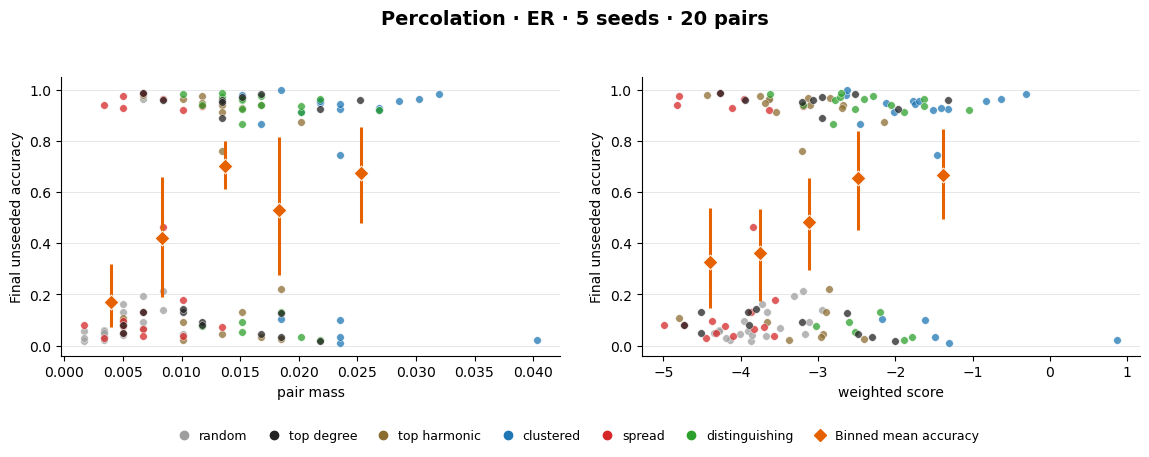

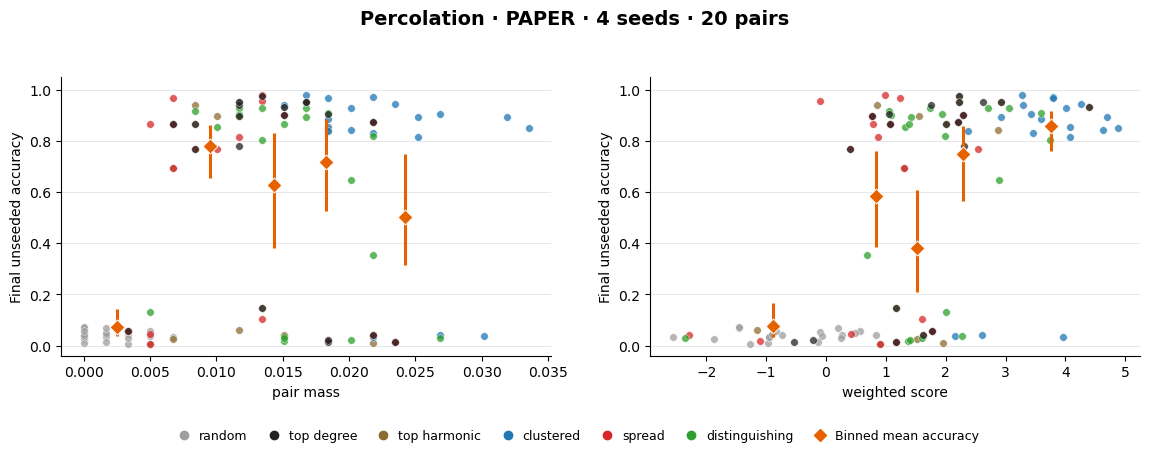

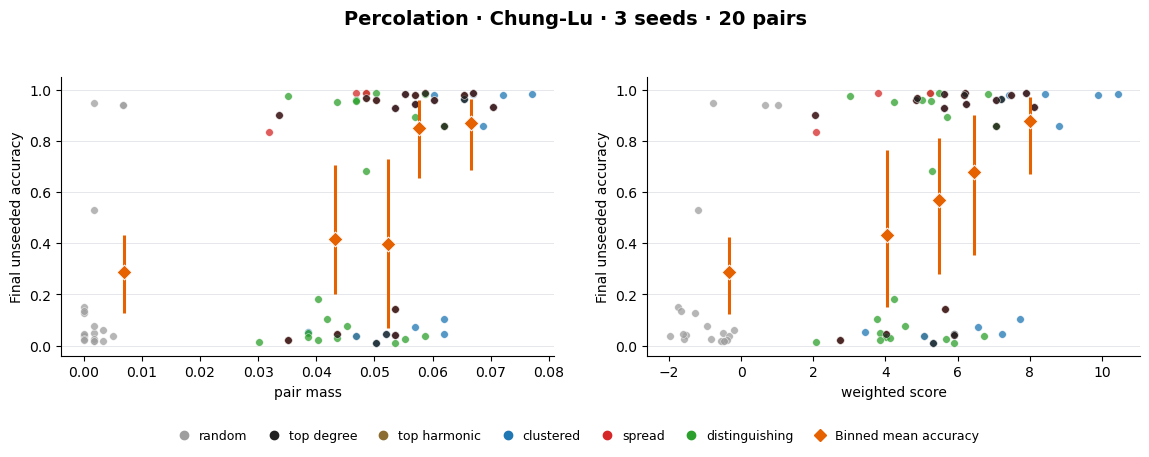

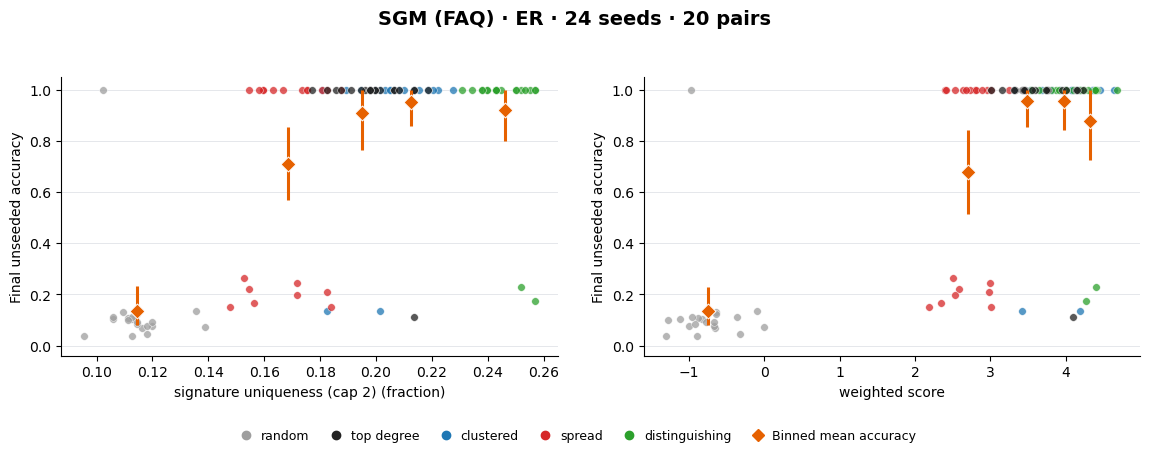

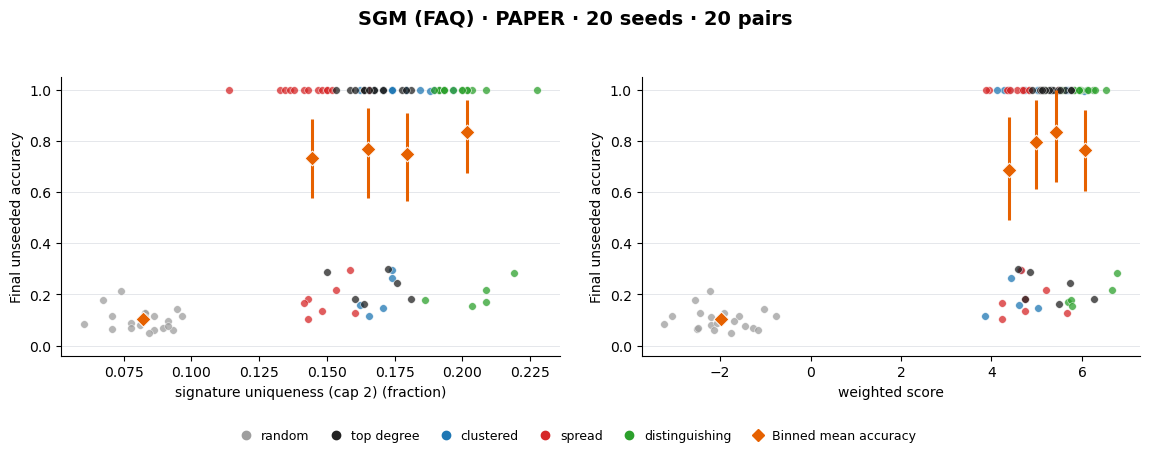

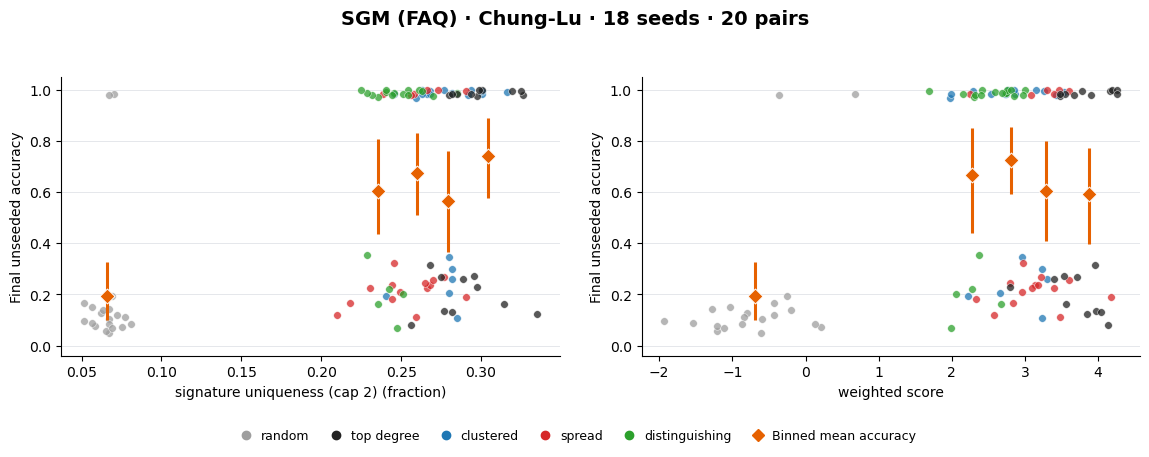

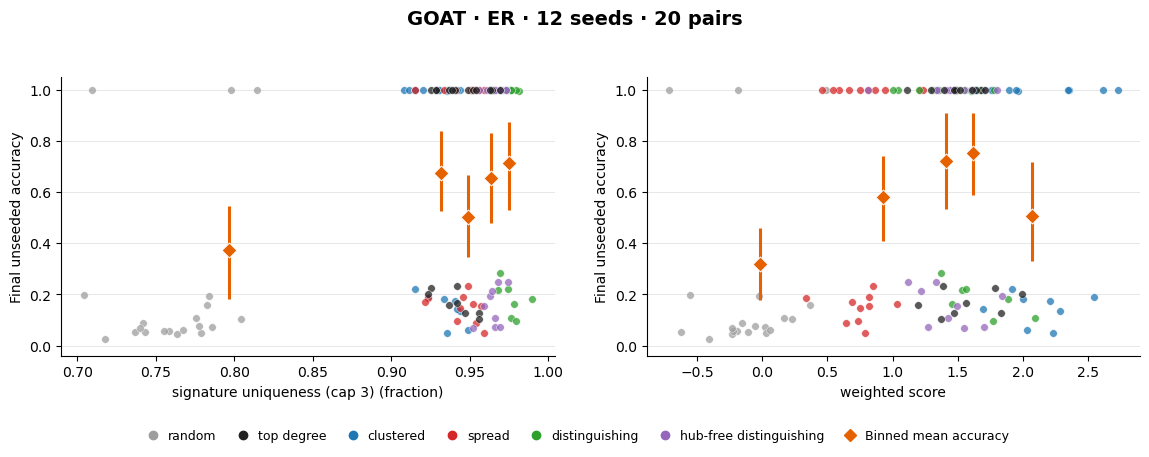

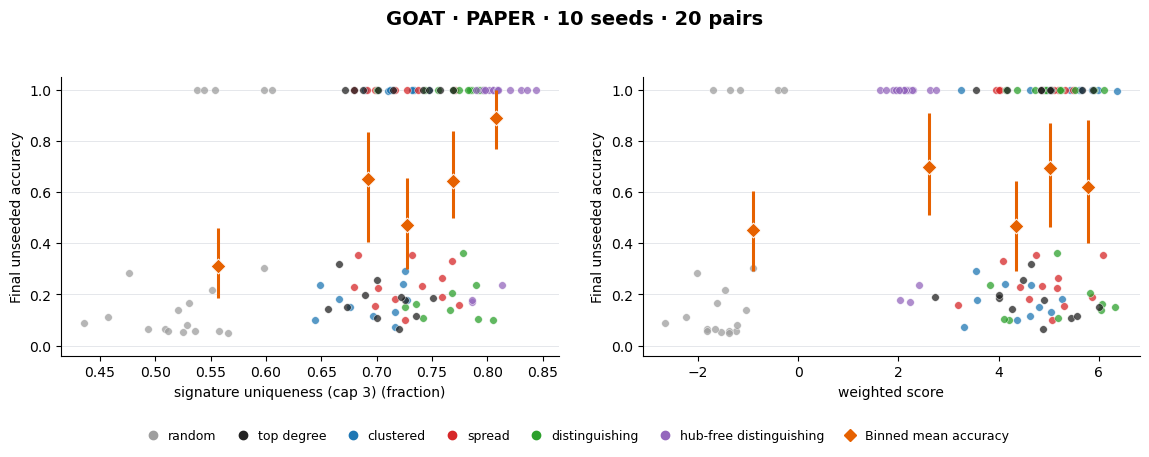

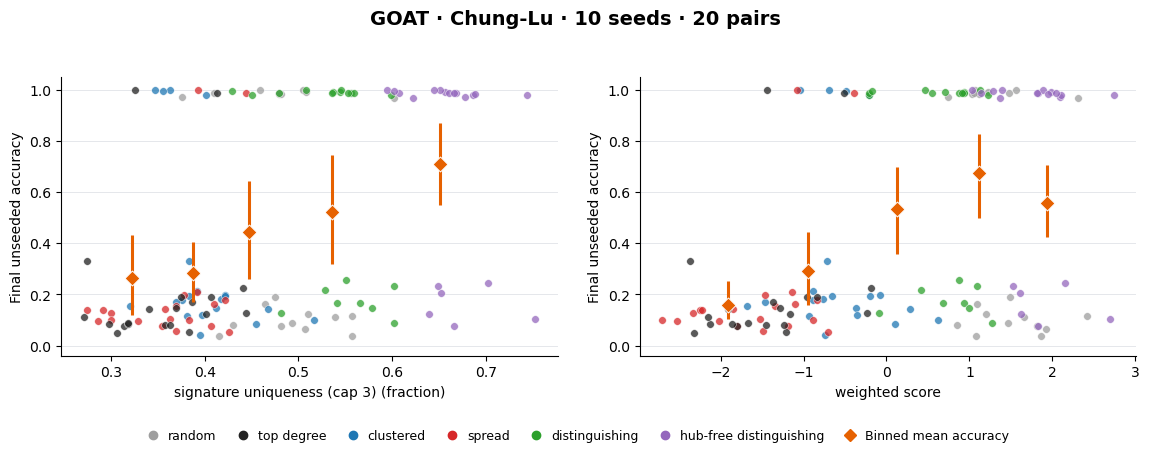

In [23]:
# Clear only this view's cached bin summaries when this cell is rerun.
scatter_bin_tables[:] = [t for t in scatter_bin_tables if t['view'].iloc[0] != 'absolute']
for algorithm, model in scatter_settings:
    scatter_data, scatter_budget, scatter_feature = scatter_panel_data(algorithm, model)
    if not SCATTER_INCLUDE_RANDOM:
        scatter_data = scatter_data[scatter_data['strategy'] != 'random'].copy()
    draw_seed_scatter(scatter_data, algorithm, model, scatter_budget, scatter_feature, paired=False)

### 10.2 Does a feature or score improvement accompany a matching improvement?

For each alternative, subtract top degree's feature, score and accuracy **on the same graph pair at the same seed budget**. The upper-right region contains alternatives that improve both x and performance. The lower-right region contains cases where the feature/score improves but performance worsens. The top-degree reference itself is omitted; random alternatives are omitted by default to focus on comparisons among designed rules.

This removes the baseline level for each pair but does not isolate a causal feature effect: alternatives change several properties simultaneously. It also does not guarantee that the feature works on every pair.

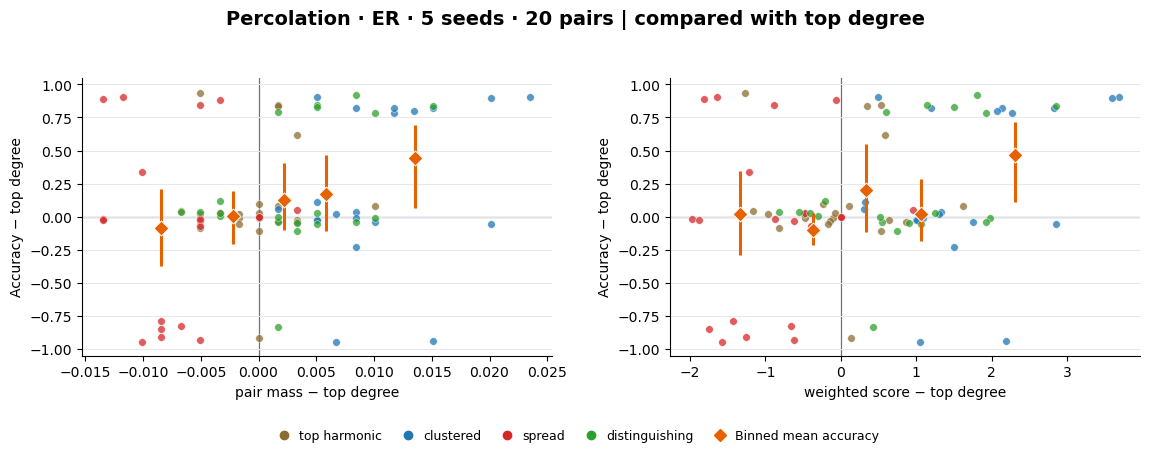

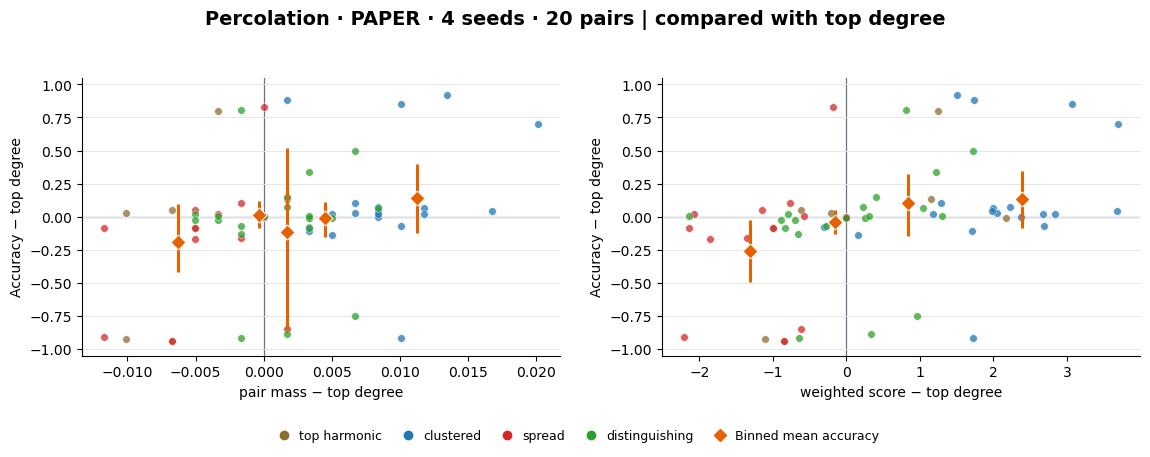

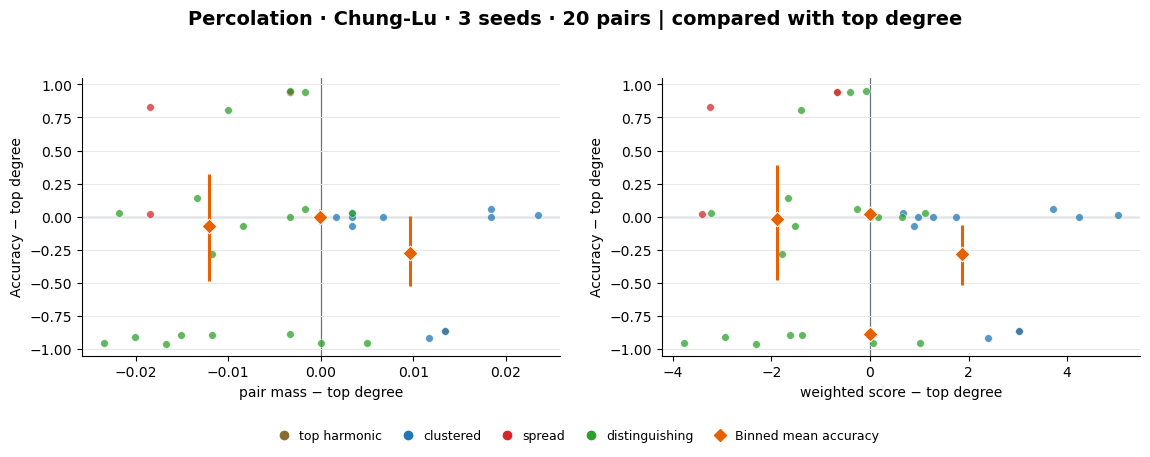

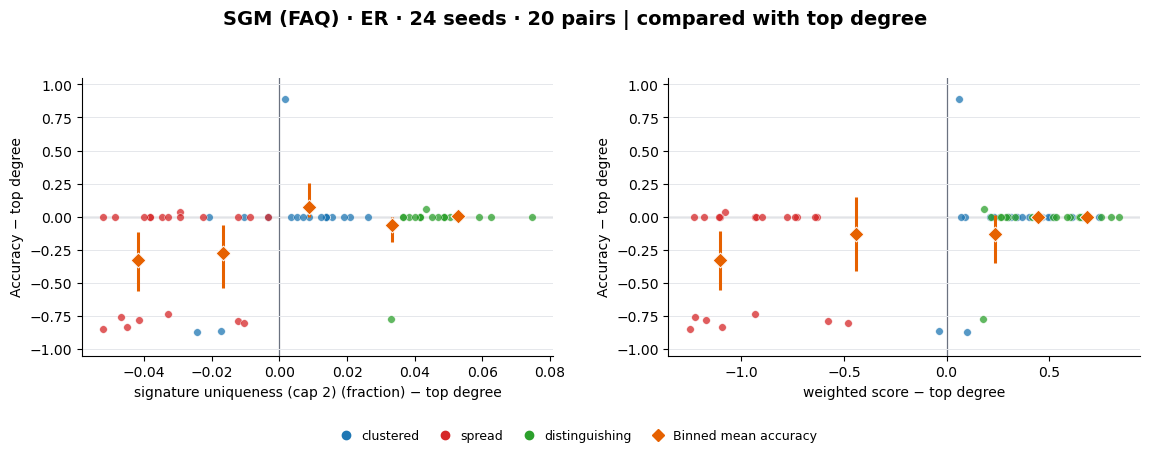

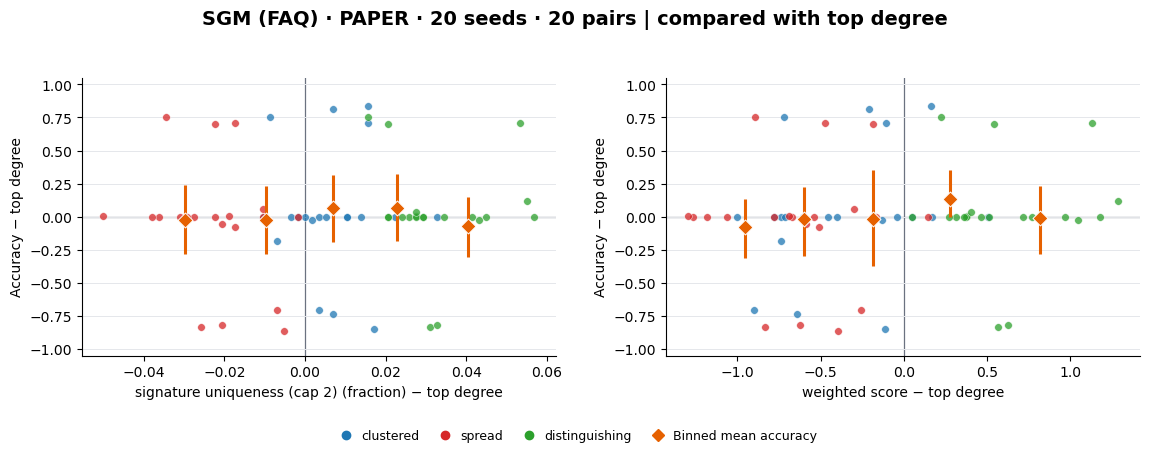

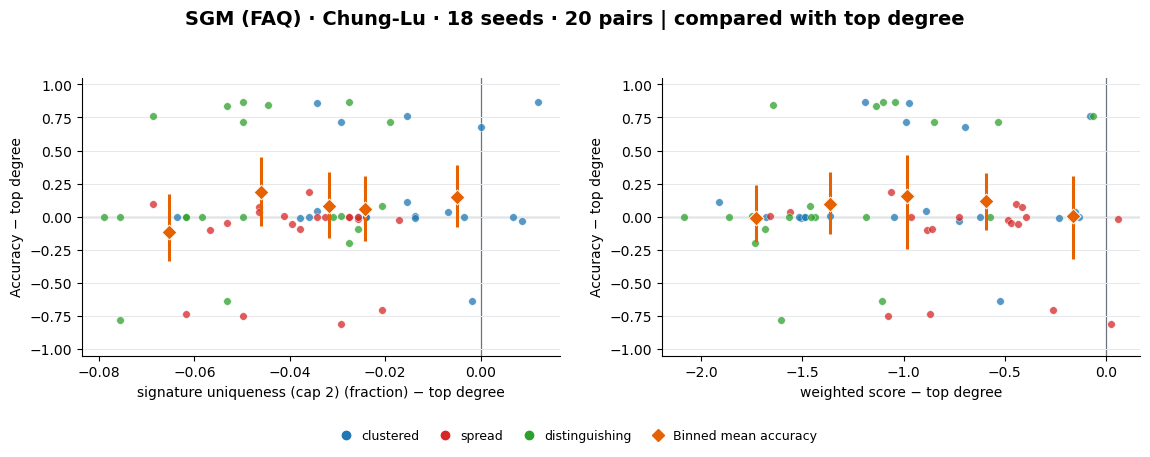

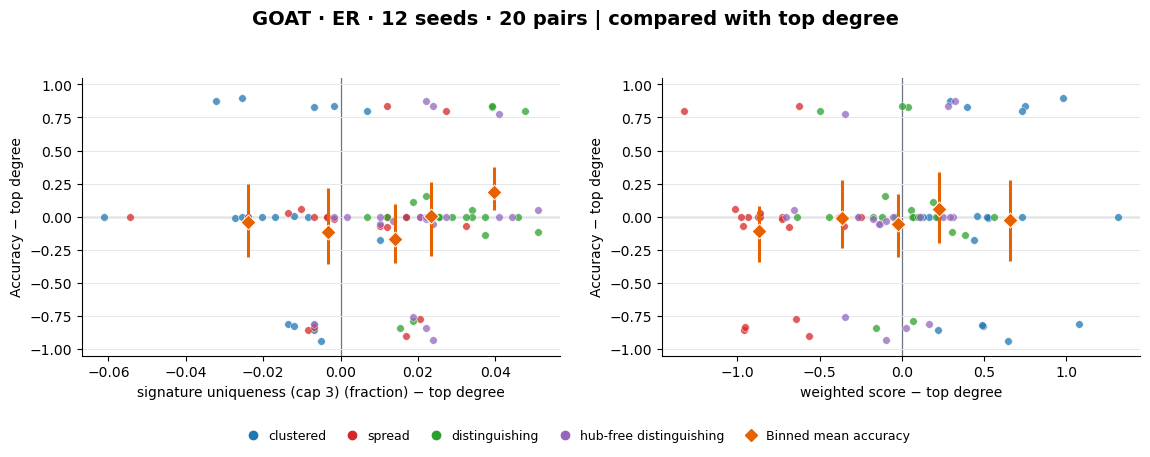

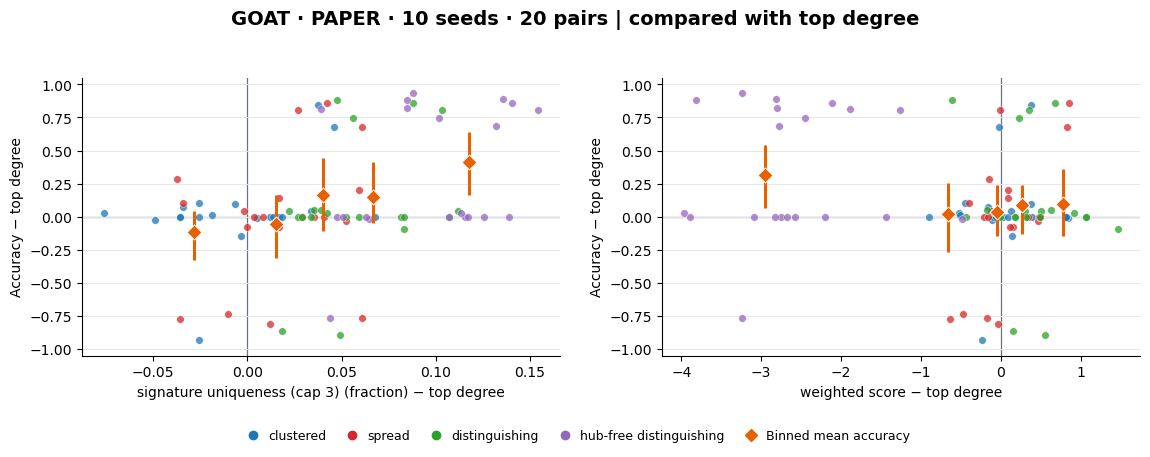

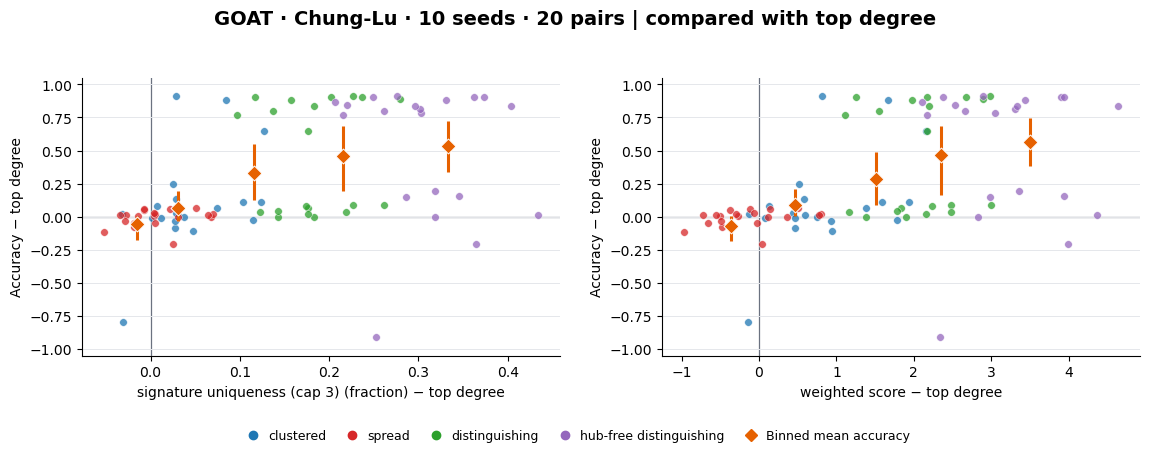

In [24]:
scatter_bin_tables[:] = [t for t in scatter_bin_tables if t['view'].iloc[0] != 'paired']
for algorithm, model in scatter_settings:
    scatter_data, scatter_budget, scatter_feature = scatter_panel_data(algorithm, model)
    scatter_changes = scatter_against_reference(scatter_data, scatter_feature,
                                                include_random=SCATTER_PAIRED_INCLUDE_RANDOM)
    draw_seed_scatter(scatter_changes, algorithm, model, scatter_budget, scatter_feature, paired=True)

### 10.3 Numerical values behind the diamonds

`n_sets` counts strategy-set evaluations (two strategies can sometimes pick the same set), and `n_pairs` counts distinct graph pairs contributing to that bin. The intervals account for dependence among strategies from the same graph pair. Sparse bins may have no reported interval. The summaries reflect the chosen strategy mixture, not uniformly random seed-set performance.

The score stays frozen from section 9. FAQ accuracy uses the objective-selected run among the available saved restarts, inheriting the existing collection protocol; its single-run training model should therefore be interpreted as a ranking score rather than a calibrated prediction of restart performance.

In [21]:
if scatter_bin_tables:
    scatter_bin_summary = pd.concat(scatter_bin_tables, ignore_index=True)
    display(scatter_bin_summary.set_index(['algorithm', 'model', 'budget', 'view', 'x_column', 'bin'])[
        ['n_sets', 'n_pairs', 'x_min', 'x_max', 'x_mean', 'mean_accuracy', 'ci_low', 'ci_high']].round(3))
else:
    print('Run the two plotting cells above first.')

n_sets  n_pairs  x_min  \
algorithm   model     budget view     x_column    bin                           
percolation sparse_er 5      absolute f_pair_mass 1        25       16  0.002   
                                                  2        26       14  0.007   
                                                  3        29       16  0.012   
                                                  4        19       11  0.017   
                                                  5        21       15  0.022   
...                                                       ...      ...    ...   
goat        chung_lu  10     paired   score       1        16       15 -0.970   
                                                  2        16       13  0.074   
                                                  3        16       14  0.928   
                                                  4        16       13  2.111   
                                                  5        16       13  2.887   

                                                       x_max  x_mean  \
algorithm   model     budget view     x_column    bin                  
percolation sparse_er 5      absolute f_pair_mass 1    0.005   0.004   
                                                  2    0.010   0.008   
                                                  3    0.015   0.014   
                                                  4    0.020   0.018   
                                                  5    0.040   0.025   
...                                                      ...     ...   
goat        chung_lu  10     paired   score       1    0.041  -0.362   
                                                  2    0.814   0.471   
                                                  3    1.983   1.512   
                                                  4    2.831   2.357   
                                                  5    4.641   3.501   

                                                       mean_accuracy  ci_low  \
algorithm   model     budget view     x_column    bin                          
percolation sparse_er 5      absolute f_pair_mass 1            0.172   0.073   
                                                  2            0.419   0.190   
                                                  3            0.701   0.610   
                                                  4            0.531   0.274   
                                                  5            0.675   0.480   
...                                                              ...     ...   
goat        chung_lu  10     paired   score       1           -0.068  -0.184   
                                                  2            0.092   0.008   
                                                  3            0.283   0.087   
                                                  4            0.465   0.164   
                                                  5            0.567   0.382   

                                                       ci_high  
algorithm   model     budget view     x_column    bin           
percolation sparse_er 5      absolute f_pair_mass 1      0.320  
                                                  2      0.658  
                                                  3      0.798  
                                                  4      0.816  
                                                  5      0.853  
...                                                        ...  
goat        chung_lu  10     paired   score       1      0.004  
                                                  2      0.210  
                                                  3      0.486  
                                                  4      0.686  
                                                  5      0.748  

[176 rows x 8 columns]

## 11. The same plots at the exact model-training budgets

Section 10 normally uses the saved budget whose **success rate pooled over all strategies is closest to 50%**, so both successful and failed sets are visible. Its configuration can override individual settings. For example, percolation ER is shown at **5 seeds**, where pooled success is about 48%; its frozen model was trained at **8 seeds**.

Here each setting uses **exactly the seed count used to fit its frozen model**, retaining the same graph-generation and solver settings. These remain the **20 comparison pairs**, distinct from the original training pair. Each model was fitted on **600 random seed sets on one fixed pair**; the original collection also contains 400 sets from other sampling schemes. The plots below evaluate the existing selection rules on the comparison pairs, without refitting the model.

Some exact training budgets were absent from the comparison grid. Their additional evaluations are saved separately in `data/round1_training_budgets`; existing round-1 files and section 10's budget choices stay as they were. Original comparison results are reused wherever the exact budget already exists. **No nearest-budget substitution or interpolation is used.**

**Run:** run the settings/loading cells at the top, the first code cell of section 9, and the configuration/helper cells in section 10, then this section. Loading and plotting do not run matchers. The optional runner is off by default and resumes any missing additional evaluations when explicitly enabled. Matching the training budget removes the seed-count difference; the selected sets still differ from the random training distribution. FAQ also retains round 1's up-to-three-restart protocol, while its training collection used one run.

In [25]:
import subprocess
import sys
from concurrent.futures import ThreadPoolExecutor, as_completed

required_training_budget_state = ['fits', 'scored', 'pair_info', 'datasets', 'draw_seed_scatter',
                                  'scatter_against_reference', 'SCATTER_FEATURE']
missing_training_budget_state = [name for name in required_training_budget_state if name not in globals()]
if missing_training_budget_state:
    raise RuntimeError('Run the prerequisites listed above first. Missing: ' + ', '.join(missing_training_budget_state))

TRAINING_BUDGET_SETTINGS = list(datasets)  # or a subset of (algorithm, model) pairs
TRAINING_BUDGET_ROOT = EXPERIMENT_DIR / 'data' / 'round1_training_budgets'
RUN_MISSING_TRAINING_BUDGETS = False       # True runs/resumes only the budgets absent from round 1
TRAINING_BUDGET_JOBS = 3                   # independent processes, one per setting
TRAINING_BUDGET_BLAS_THREADS = 3

training_budget_jobs, training_budget_rows = [], []
for algorithm, model in TRAINING_BUDGET_SETTINGS:
    fit = fits[(algorithm, model)]
    budget = fit['n_seeds']
    original = scored[(scored['algorithm'] == algorithm) & (scored['model'] == model)]
    reference_pairs = pair_info[(pair_info['algorithm'] == algorithm) & (pair_info['model'] == model)]
    pair_indices = sorted(reference_pairs['pair_index'].unique())
    if pair_indices != list(range(len(pair_indices))):
        raise ValueError('The supplemental runner requires the original contiguous pair indices starting at 0.')
    settings = json.loads((ROUND_DIR / PHASE / algorithm / model / 'settings.json').read_text())
    has_exact = budget in set(original['budget'])
    folder = TRAINING_BUDGET_ROOT / PHASE / algorithm / model
    completed = 0
    if not has_exact:
        if (folder / 'pairs.csv').exists():
            completed = len(set(pd.read_csv(folder / 'pairs.csv')['pair_index']) & set(pair_indices))
        command = [sys.executable, '-m', 'selection_rule_comparison.run_comparison',
                   '--algorithm', algorithm, '--model', model, '--phase', PHASE,
                   '--pairs', str(len(pair_indices)), '--budgets', str(budget),
                   '--strategies', *settings['strategies'],
                   '--faq-restarts', str(settings['solver'].get('max_restarts', 3)),
                   '--blas-threads', str(TRAINING_BUDGET_BLAS_THREADS), '--jobs', '1',
                   '--output-root', str(TRAINING_BUDGET_ROOT), '--no-caffeinate']
        training_budget_jobs.append(dict(algorithm=algorithm, model=model, budget=budget,
                                         command=command, expected_pairs=len(pair_indices),
                                         completed_pairs=completed))
    training_budget_rows.append({
        'algorithm': ALGORITHM_LABELS[algorithm], 'model': MODEL_LABELS[model],
        'training seeds': budget,
        'section 10 seeds': SCATTER_BUDGETS.get((algorithm, model), plot_budgets[(algorithm, model)]),
        'random training sets': fit['n_sets'],
        'source': 'original comparison' if has_exact else 'additional exact-budget comparison',
        'saved pairs': len(pair_indices) if has_exact else completed,
        'expected pairs': len(pair_indices),
    })
training_budget_plan = pd.DataFrame(training_budget_rows).set_index(['algorithm', 'model'])
display(training_budget_plan)

training seeds  section 10 seeds  random training sets                              source  saved pairs  expected pairs
algorithm   model                                                                                                                            
Percolation ER                     8                 5                   600                 original comparison           20              20
            PAPER                  7                 4                   600  additional exact-budget comparison           20              20
            Chung-Lu               5                 3                   600                 original comparison           20              20
SGM (FAQ)   ER                    29                24                   600  additional exact-budget comparison           20              20
            PAPER                 31                20                   600  additional exact-budget comparison           20              20
            Chung-Lu              27                18                   600  additional exact-budget comparison           20              20
GOAT        ER                    12                12                   600                 original comparison           20              20
            PAPER                 12                10                   600                 original comparison           20              20
            Chung-Lu               9                10                   600  additional exact-budget comparison           20              20

### Optional: collect or resume missing budgets

Leave `RUN_MISSING_TRAINING_BUDGETS = False` to use saved results. If it is enabled, this cell invokes the existing comparison runner on the same pair indices, strategies and restart protocol, using a separate results folder. Completed pairs are reused. Progress is written to the additional-results folder's `logs/` directory. Avoid launching the same additional setting concurrently in another kernel.

In [26]:
if RUN_MISSING_TRAINING_BUDGETS and training_budget_jobs:
    log_dir = TRAINING_BUDGET_ROOT / 'logs'
    log_dir.mkdir(parents=True, exist_ok=True)
    def run_training_budget_job(job):
        log_path = log_dir / f"{PHASE}_{job['algorithm']}_{job['model']}_k{job['budget']}.log"
        with log_path.open('a') as log:
            subprocess.run(job['command'], cwd=EXPERIMENT_DIR.parent, stdout=log,
                           stderr=subprocess.STDOUT, check=True)
        return f"{ALGORITHM_LABELS[job['algorithm']]} / {MODEL_LABELS[job['model']]}: complete ({log_path})"
    print('Running/resuming additional budgets. Progress logs:', log_dir, flush=True)
    with ThreadPoolExecutor(max_workers=min(TRAINING_BUDGET_JOBS, len(training_budget_jobs))) as pool:
        futures = [pool.submit(run_training_budget_job, job) for job in training_budget_jobs]
        for future in as_completed(futures):
            print(future.result(), flush=True)
else:
    print('Using saved results. Enable RUN_MISSING_TRAINING_BUDGETS above to collect/resume missing budgets.')

Using saved results. Enable RUN_MISSING_TRAINING_BUDGETS above to collect/resume missing budgets.


In [27]:
if any((TRAINING_BUDGET_ROOT / PHASE).glob('*/*/runs.csv')):
    training_budget_extra, training_budget_extra_pairs, _ = load_round(PHASE, round_dir=TRAINING_BUDGET_ROOT)
else:
    training_budget_extra = pd.DataFrame()
    training_budget_extra_pairs = pd.DataFrame()

training_budget_frames, training_budget_status_rows = {}, []
for algorithm, model in TRAINING_BUDGET_SETTINGS:
    fit = fits[(algorithm, model)]
    budget = fit['n_seeds']
    original = scored[(scored['algorithm'] == algorithm) & (scored['model'] == model)]
    references = pair_info[(pair_info['algorithm'] == algorithm) & (pair_info['model'] == model)]
    original_settings = json.loads((ROUND_DIR / PHASE / algorithm / model / 'settings.json').read_text())
    if budget in set(original['budget']):
        data = original[original['budget'] == budget].copy()
    elif not training_budget_extra.empty:
        data = training_budget_extra[(training_budget_extra['algorithm'] == algorithm) &
                                     (training_budget_extra['model'] == model) &
                                     (training_budget_extra['budget'] == budget)].copy()
        if not data.empty:
            actual_settings = json.loads((TRAINING_BUDGET_ROOT / PHASE / algorithm / model / 'settings.json').read_text())
            if actual_settings['budgets'] != [budget]:
                raise ValueError(f'{algorithm}/{model}: additional results do not use the exact training budget.')
            for field in original_settings:
                if field != 'budgets' and actual_settings.get(field) != original_settings[field]:
                    raise ValueError(f'{algorithm}/{model}: additional setting differs in {field}.')
            extra_pairs = training_budget_extra_pairs[(training_budget_extra_pairs['algorithm'] == algorithm) &
                                                       (training_budget_extra_pairs['model'] == model)]
            fields = ['pair_seed', 'hash_a', 'hash_b']
            reference_hashes = references.set_index('pair_index')[fields]
            actual_hashes = extra_pairs.set_index('pair_index')[fields]
            used = sorted(data['pair_index'].unique())
            if not set(used).issubset(reference_hashes.index):
                raise ValueError(f'{algorithm}/{model}: additional results contain different pair indices.')
            if not actual_hashes.loc[used].equals(reference_hashes.loc[used]):
                raise ValueError(f'{algorithm}/{model}: regenerated graph pairs do not match the original hashes.')
    else:
        data = pd.DataFrame()
    expected_pairs = len(references)
    if not data.empty:
        expected_strategies = set(original_settings['strategies'])
        if data.duplicated(['pair_index', 'strategy']).any():
            raise ValueError(f'{algorithm}/{model}: duplicate exact-budget evaluations.')
        if set(data['strategy']) != expected_strategies:
            raise ValueError(f'{algorithm}/{model}: different strategies in exact-budget results.')
        counts = data.groupby('pair_index')['strategy'].nunique()
        data = data[data['pair_index'].isin(counts[counts == len(expected_strategies)].index)].copy()
        Z = (data[fit['features']].to_numpy(float) - fit['mean']) / fit['sd']
        data['score'] = Z @ fit['weights']
        if not np.isfinite(data[[*fit['features'], 'score', 'accuracy']].to_numpy(float)).all():
            raise ValueError(f'{algorithm}/{model}: nonfinite exact-budget data.')
        if not data.empty:
            training_budget_frames[(algorithm, model)] = data
    saved_pairs = 0 if data.empty else data['pair_index'].nunique()
    training_budget_status_rows.append({
        'algorithm': ALGORITHM_LABELS[algorithm], 'model': MODEL_LABELS[model],
        'seeds': budget, 'saved pairs': saved_pairs, 'expected pairs': expected_pairs,
        'status': 'complete' if saved_pairs == expected_pairs else 'partial' if saved_pairs else 'missing',
    })
training_budget_status = pd.DataFrame(training_budget_status_rows).set_index(['algorithm', 'model'])
display(training_budget_status)
if not training_budget_status['status'].eq('complete').all():
    print('Some exact budgets are missing/partial. Enable the optional runner above; only available complete pairs are plotted.')
training_budget_bin_tables = []

seeds  saved pairs  expected pairs    status
algorithm   model                                                 
Percolation ER            8           20              20  complete
            PAPER         7           20              20  complete
            Chung-Lu      5           20              20  complete
SGM (FAQ)   ER           29           20              20  complete
            PAPER        31           20              20  complete
            Chung-Lu     27           20              20  complete
GOAT        ER           12           20              20  complete
            PAPER        12           20              20  complete
            Chung-Lu      9           20              20  complete

### 11.1 Actual feature values and weighted score at the training budget

These are section 10.1's plots with the seed count fixed to the model's exact training budget. Orange diamonds and bars use the same binning and graph-pair bootstrap. All other plotting choices are inherited from section 10, including `SCATTER_FEATURE` and whether random sets are included.

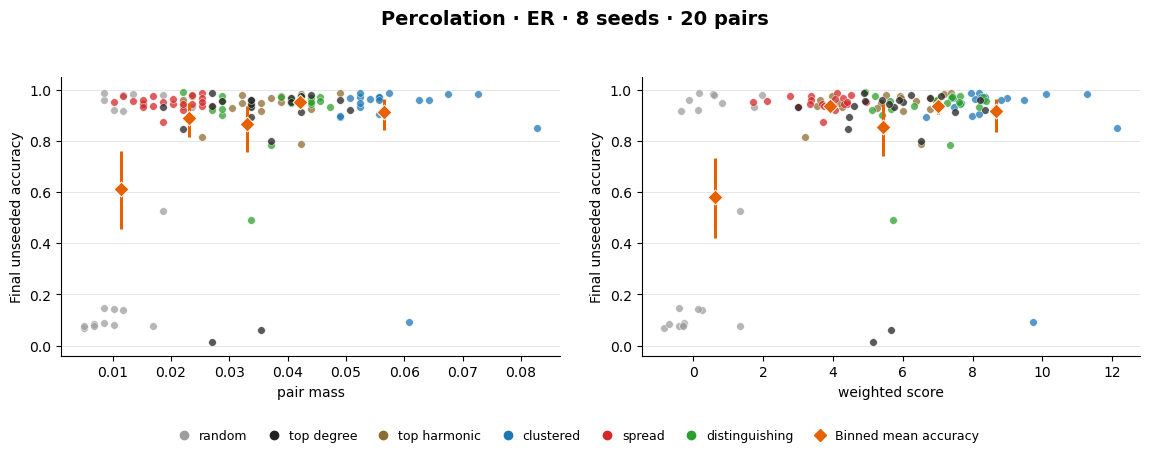

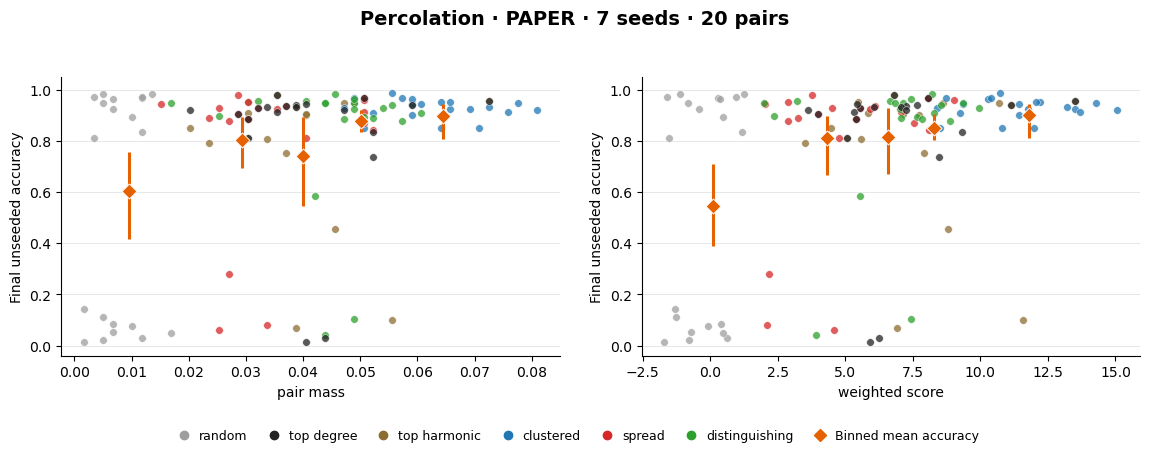

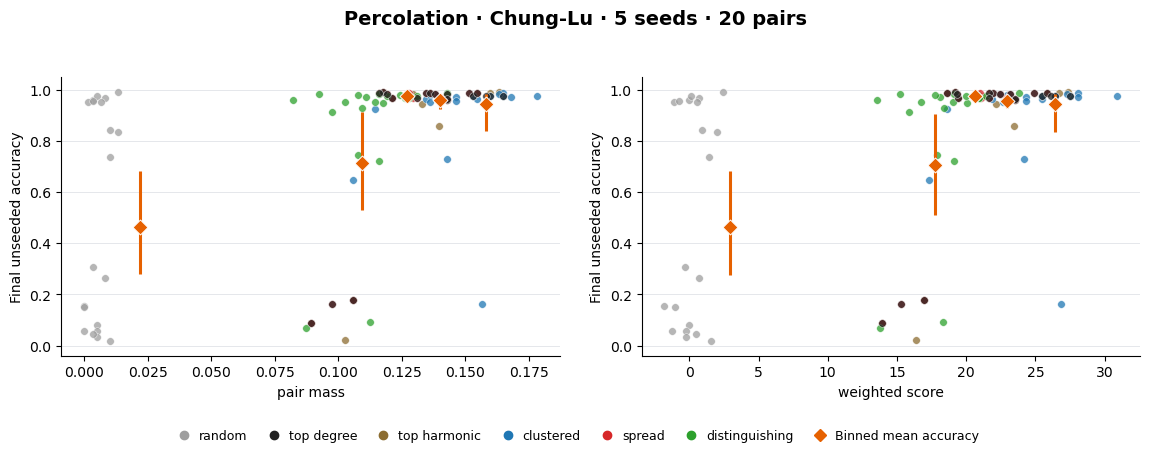

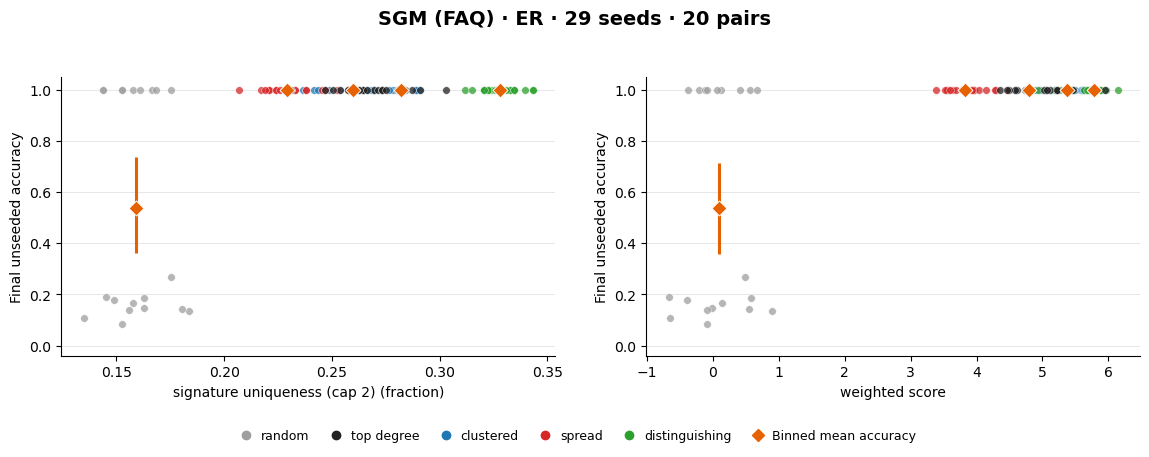

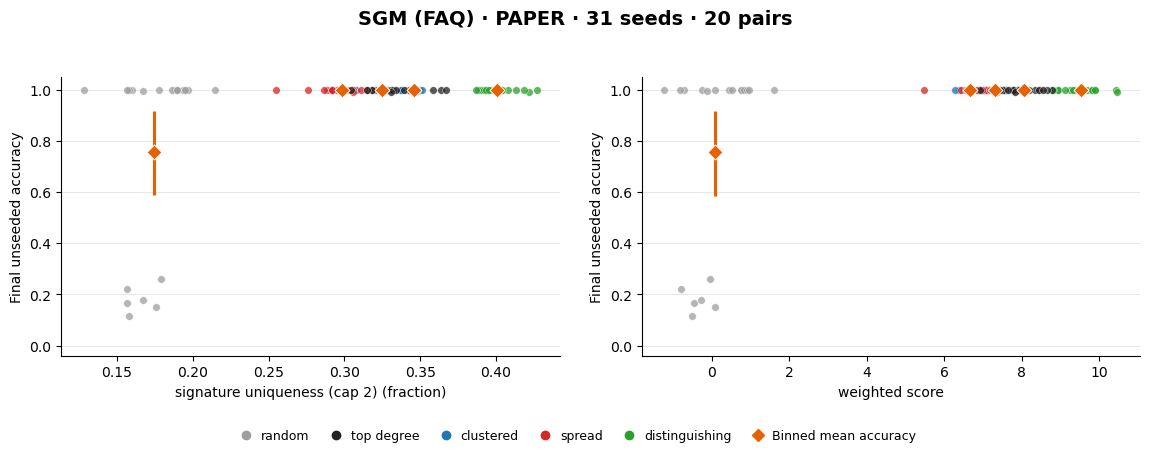

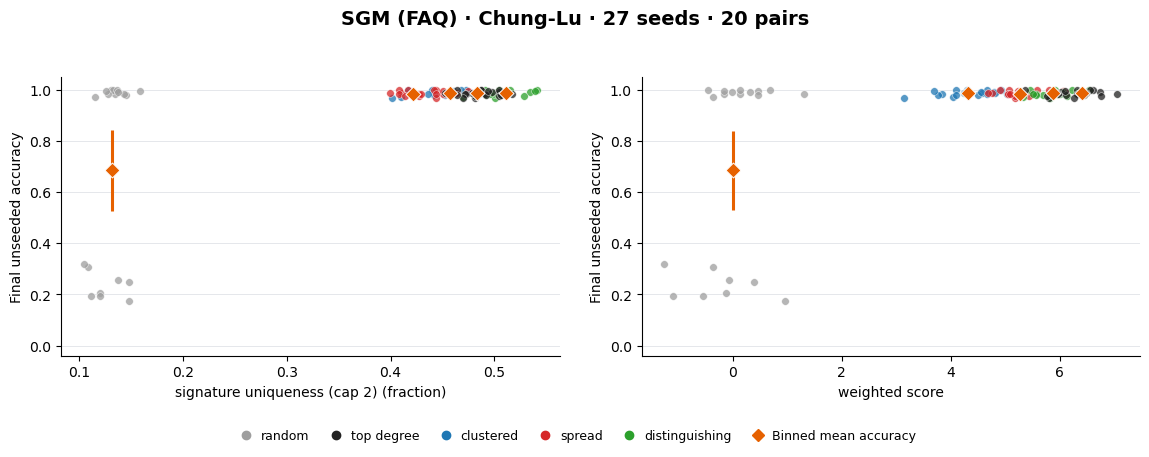

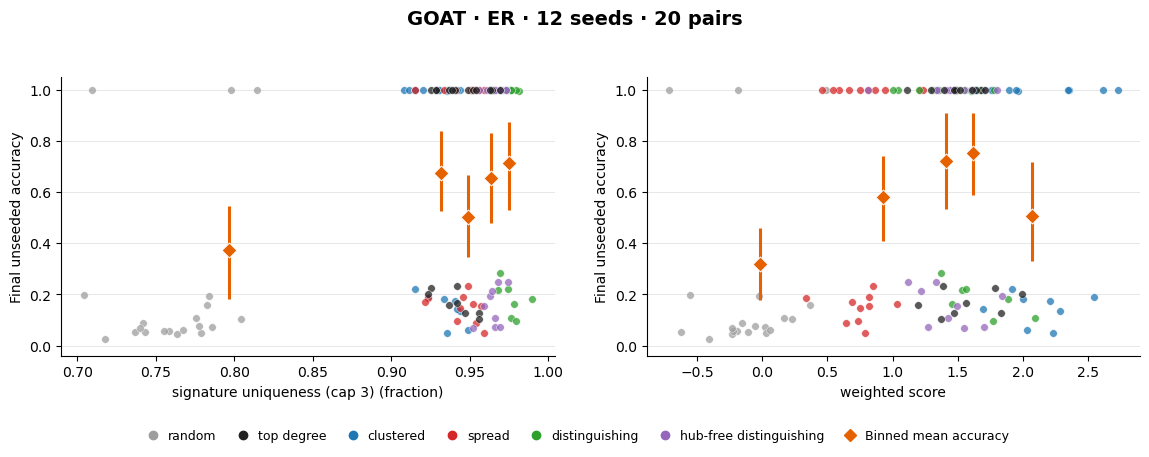

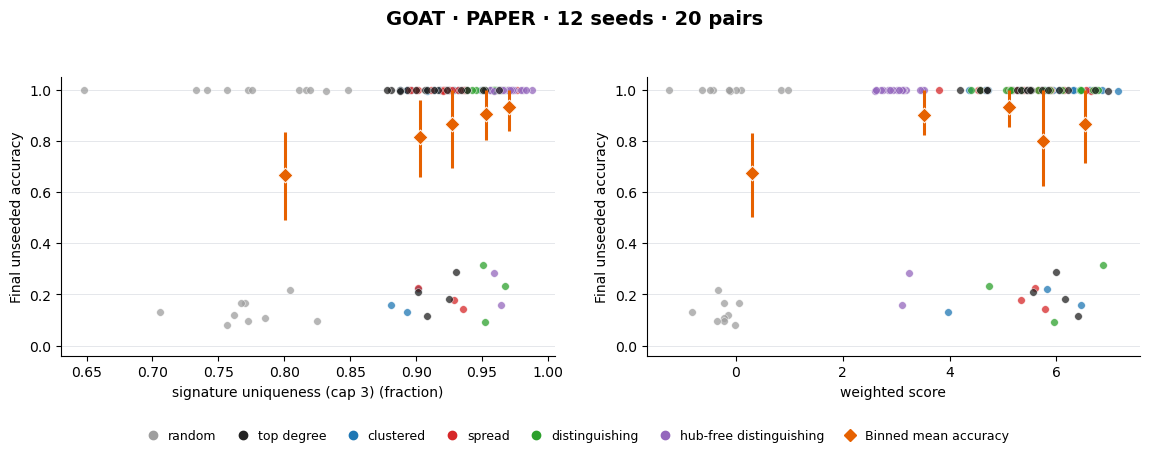

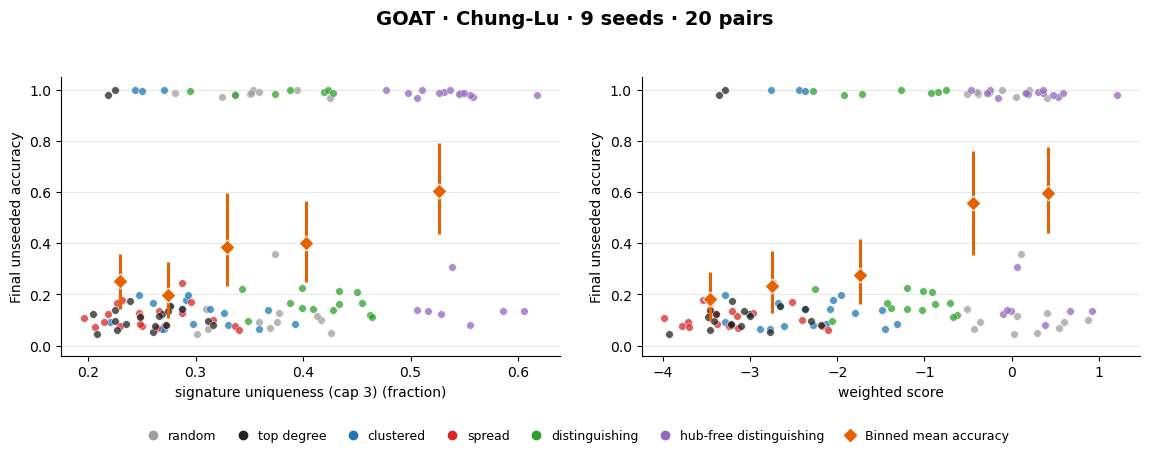

In [28]:
training_budget_bin_tables[:] = [t for t in training_budget_bin_tables if t['view'].iloc[0] != 'absolute']
for (algorithm, model), data in training_budget_frames.items():
    feature = KEY_FEATURE[algorithm] if SCATTER_FEATURE == 'key' else SCATTER_FEATURE
    plotted = data if SCATTER_INCLUDE_RANDOM else data[data['strategy'] != 'random'].copy()
    draw_seed_scatter(plotted, algorithm, model, fits[(algorithm, model)]['n_seeds'], feature,
                      paired=False, bin_tables=training_budget_bin_tables,
                      figure_prefix='training_budget_seed_scatter')

### 11.2 Changes relative to top degree at the training budget

These are section 10.2's within-pair comparisons at the exact training budget. Random sets are omitted by default, following `SCATTER_PAIRED_INCLUDE_RANDOM`. An almost flat row of accuracy differences can occur when most designed strategies already succeed at this larger budget; that is why section 10 also examines budgets nearer the transition.

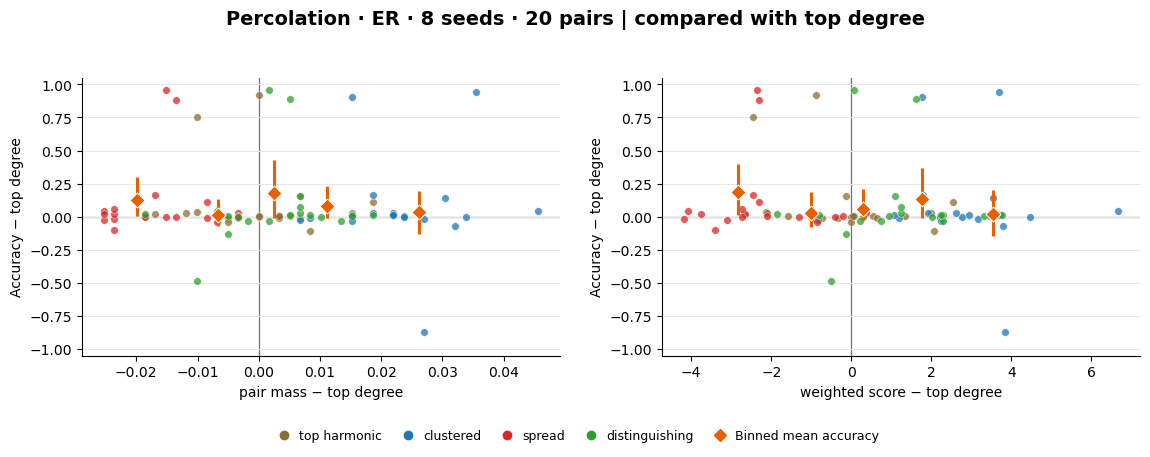

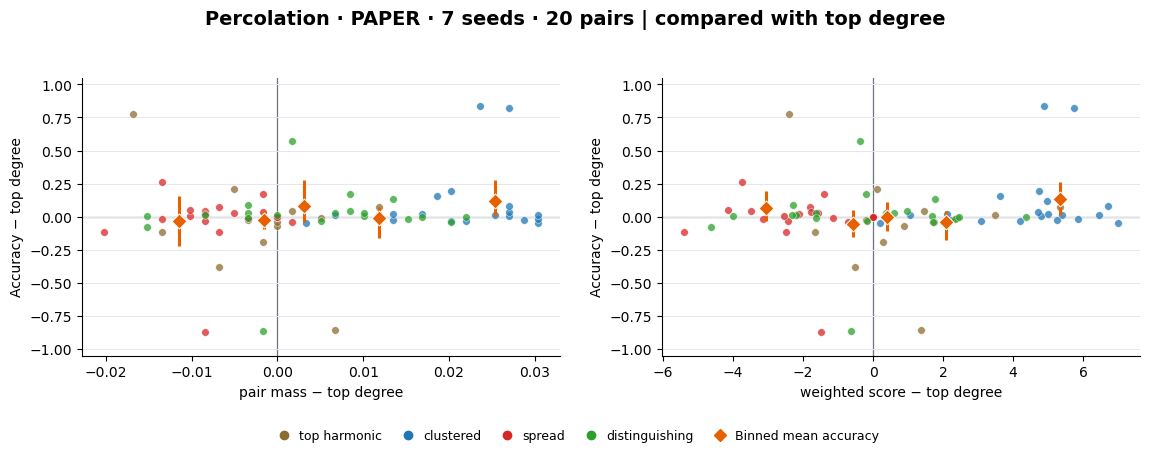

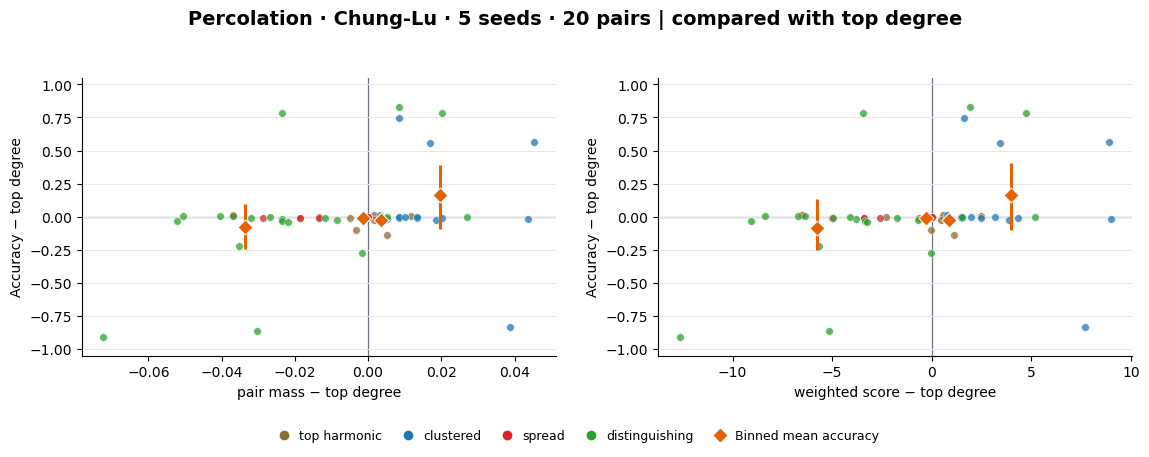

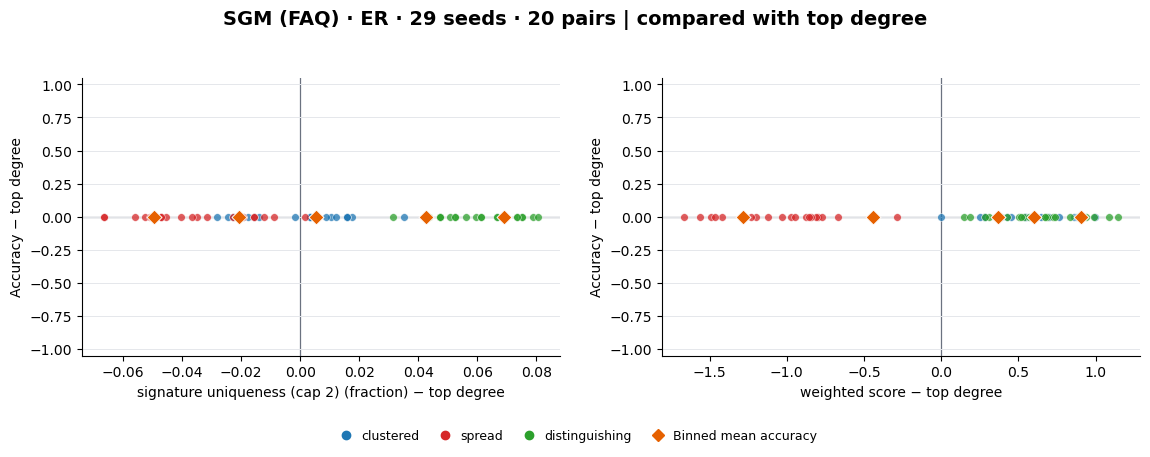

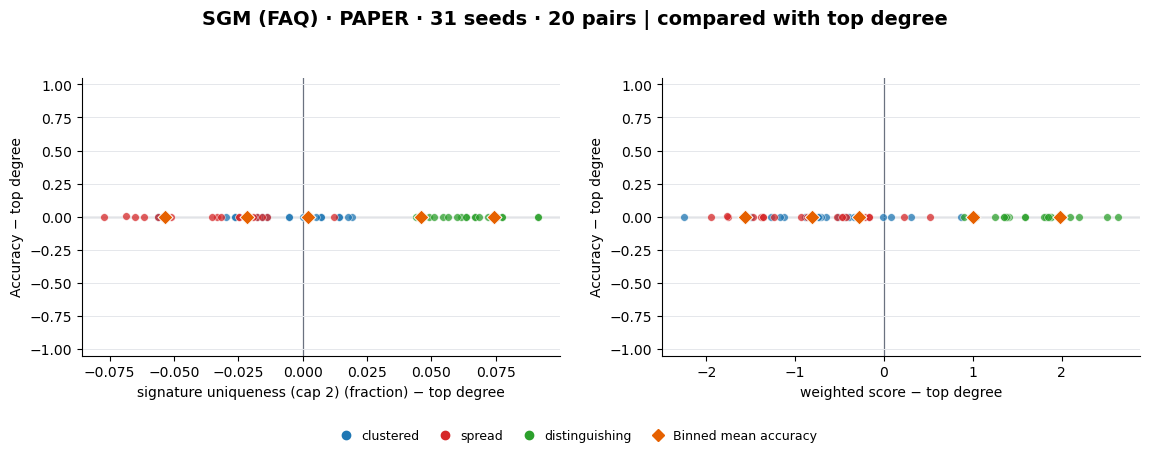

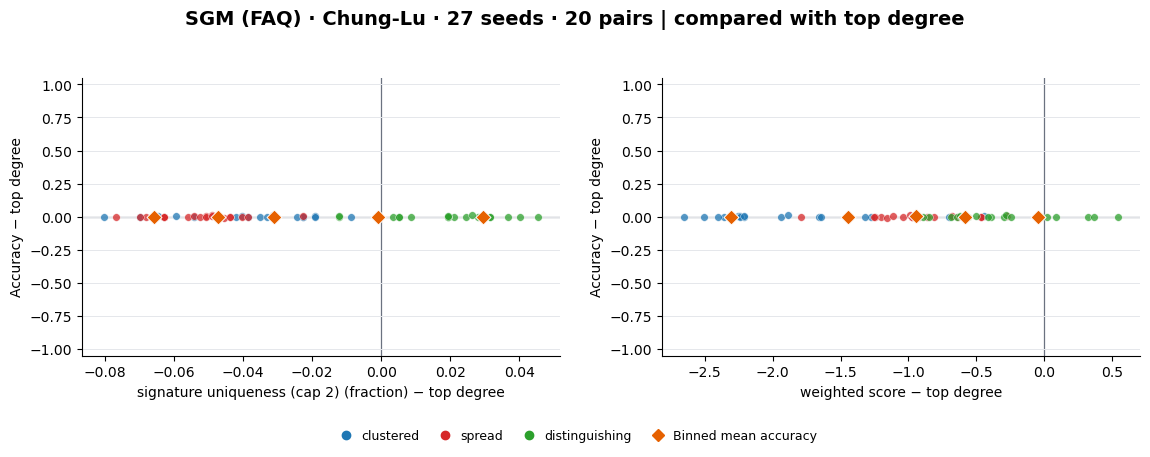

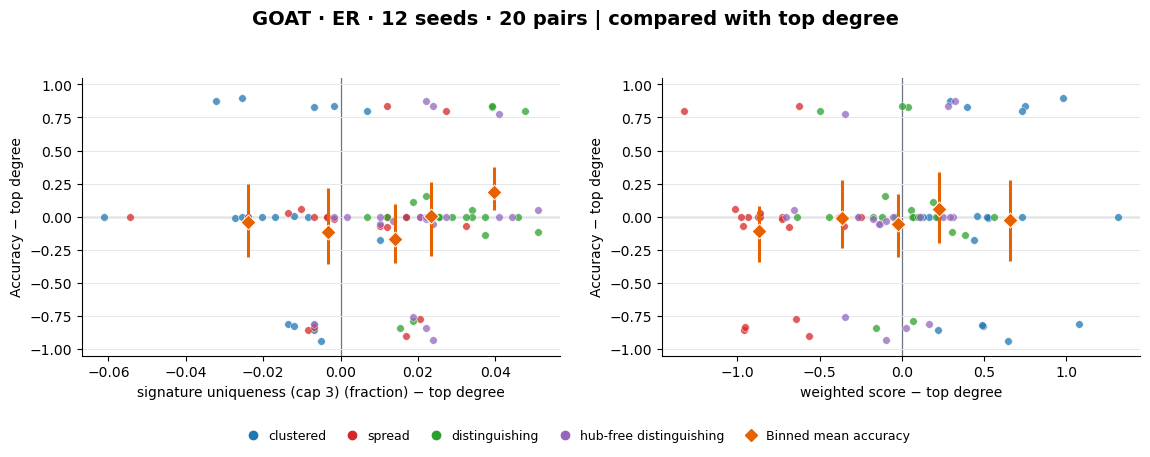

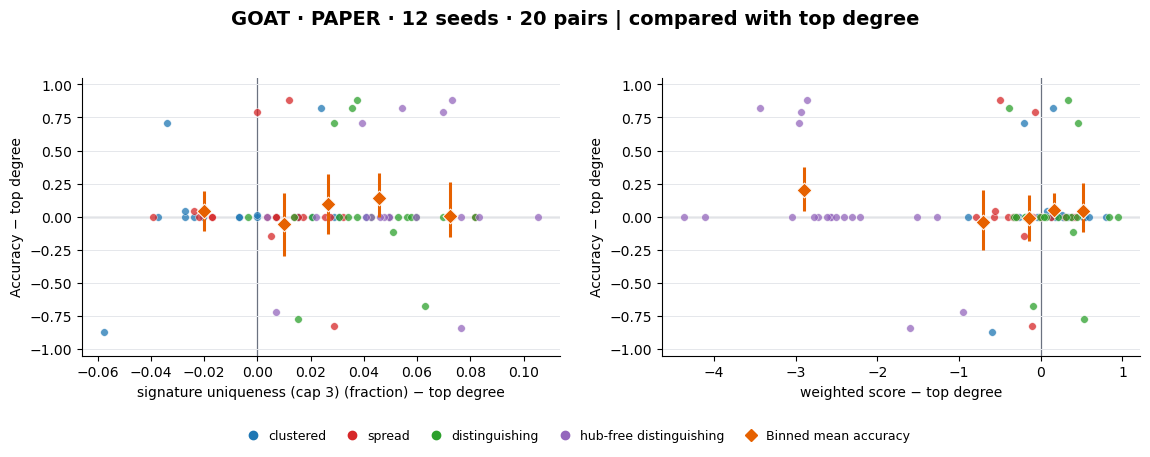

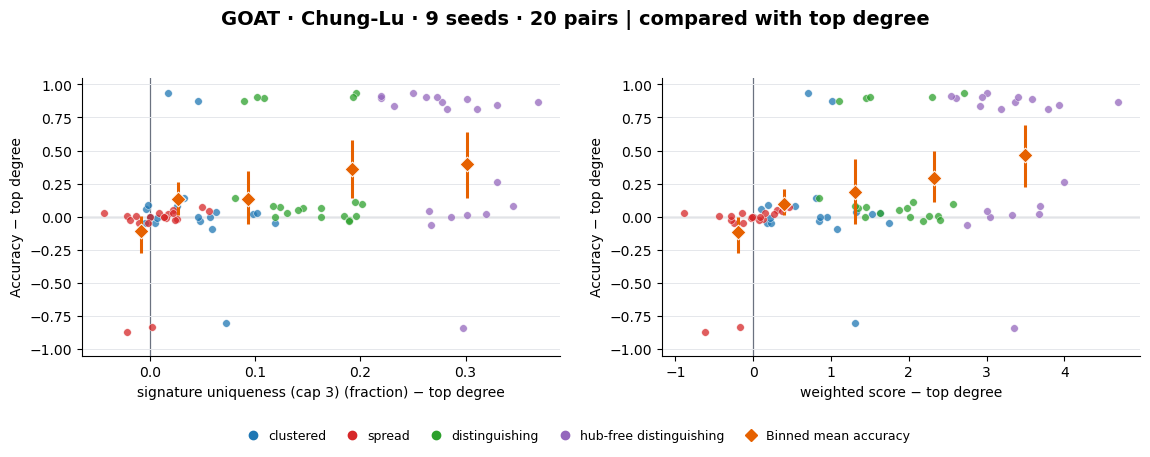

In [29]:
training_budget_bin_tables[:] = [t for t in training_budget_bin_tables if t['view'].iloc[0] != 'paired']
for (algorithm, model), data in training_budget_frames.items():
    feature = KEY_FEATURE[algorithm] if SCATTER_FEATURE == 'key' else SCATTER_FEATURE
    changes = scatter_against_reference(data, feature, include_random=SCATTER_PAIRED_INCLUDE_RANDOM)
    draw_seed_scatter(changes, algorithm, model, fits[(algorithm, model)]['n_seeds'], feature,
                      paired=True, bin_tables=training_budget_bin_tables,
                      figure_prefix='training_budget_seed_scatter')

### 11.3 Numerical values behind the training-budget plots

These summaries are separate from section 10's bin table. Matching the training budget helps compare feature ranges, but does not make the weighted score a calibrated success probability on new graph pairs.

In [30]:
if training_budget_bin_tables:
    training_budget_bin_summary = pd.concat(training_budget_bin_tables, ignore_index=True)
    display(training_budget_bin_summary.set_index(['algorithm', 'model', 'budget', 'view', 'x_column', 'bin'])[
        ['n_sets', 'n_pairs', 'x_min', 'x_max', 'x_mean', 'mean_accuracy', 'ci_low', 'ci_high']].round(3))
else:
    print('Run the two training-budget plotting cells above first.')

n_sets  n_pairs   x_min   x_max  x_mean  mean_accuracy  ci_low  ci_high
algorithm   model     budget view     x_column       bin                                                                         
percolation sparse_er 8      absolute f_pair_mass    1        25       20   0.005   0.017   0.011          0.612   0.455    0.759
                                                     2        27       18   0.019   0.027   0.023          0.890   0.814    0.947
                                                     3        21       17   0.029   0.037   0.033          0.864   0.756    0.936
                                                     4        23       15   0.039   0.046   0.042          0.952   0.930    0.965
                                                     5        24       20   0.047   0.083   0.056          0.914   0.841    0.963
                                      score          1        24       20  -0.825   3.009   0.629          0.580   0.420    0.733
                                                     2        24       19   3.015   4.507   3.919          0.936   0.918    0.952
                                                     3        24       16   4.617   6.014   5.441          0.855   0.739    0.944
                                                     4        24       14   6.235   7.498   7.009          0.935   0.905    0.962
                                                     5        24       16   7.603  12.145   8.659          0.916   0.835    0.964
            paper_pa  7      absolute f_pair_mass    1        24       20   0.002   0.020   0.009          0.604   0.416    0.755
                                                     2        24       12   0.024   0.034   0.029          0.801   0.694    0.892
                                                     3        24       14   0.035   0.046   0.040          0.742   0.546    0.893
                                                     4        24       14   0.047   0.054   0.050          0.878   0.835    0.922
                                                     5        24       16   0.056   0.081   0.065          0.895   0.808    0.942
                                      score          1        24       20  -1.694   2.173   0.125          0.545   0.389    0.708
                                                     2        24       12   2.382   5.543   4.329          0.810   0.668    0.898
                                                     3        24       13   5.558   7.422   6.598          0.817   0.672    0.926
                                                     4        24       13   7.438   9.314   8.294          0.849   0.804    0.906
                                                     5        24       16   9.340  15.071  11.796          0.899   0.812    0.945
            chung_lu  5      absolute f_pair_mass    1        25       20   0.000   0.089   0.022          0.465   0.280    0.680
                                                     2        26       14   0.092   0.118   0.109          0.714   0.529    0.914
                                                     3        22        9   0.119   0.134   0.127          0.974   0.966    0.981
                                                     4        23       10   0.136   0.143   0.140          0.959   0.923    0.979
                                                     5        24       11   0.146   0.178   0.158          0.944   0.837    0.981
                                      score          1        25       20  -1.812  13.898   2.914          0.465   0.278    0.680
                                                     2        25       14  15.214  19.155  17.712          0.704   0.509    0.904
                                                     3        22       10  19.332  21.678  20.616          0.975   0.968    0.980
                                                     4        24       11  21.838  24.183  22.953          0.957   0.928    0.977
                            